# Predicting weekday commute duration with the 2022 NHTS

**StatProj | LS03 - Team 1**  
**Current milestone:** Exploratory data analysis (EDA) completed; next, the baseline evaluation.  
**Initial dictionary review:** 15 November 2026 (Asia/Singapore).  
**Structural presentation revised:** 17 November 2026 (Asia/Singapore).

For adults making weekday home-based work trips in the United States, how accurately
can home-work distance, planned transport mode, departure period, trip direction,
and broad residential context predict reported trip duration immediately before departure,
once the planned mode is known?

The unit of observation is one trip record. The target is `TRVLCMIN`, in minutes.
The intended estimand is the **conditional median of duration given the predictors**.
This is a research choice from the project context, not an EDA finding. Claims will be
predictive and associational. Any change to this estimand requires review before modeling.

**Where the work stands.** Source inspection, the Data Dictionary, and training-data EDA are
complete. The next step is to evaluate a training-median baseline using household-grouped
cross-validation within the Train partition. No model has been fitted and no test-set
evaluation has been run. The decisions carried forward are summarized in
**EDA checkpoint and handoff to modelling**, the final section of this notebook.

- **Sample.** The EDA used a calendar definition of weekday, Monday through Friday. The sample
  has 4,393 home-based work trips by adults aged 18 or older. Of these, 4,354 trips are in the
  four mode groups named in the proposal and 39 are kept under "Other study modes". The mode
  scope for the main model remains to be decided.
- **Partition.** The household-grouped split gives 3,516 Train trips and 877 Test trips. In Train,
  3,513 trips have an observed duration; their unweighted median is 20 minutes.

## 1. Evidence status and existing work

| Evidence category | Current status |
|---|---|
| Proposal and study design | The proposed population is adults aged at least 18, weekday home-based work trips, and car/public transport/walking/cycling. The conditional median and household-grouped validation remain the intended design. Instructor approval has not been established in this session. |
| Historical project artifacts | `NHTS_2022_data_exploration.ipynb`, `NHTS_2022_correlation_analysis.ipynb`, and `NHTS_2022_research_directions.ipynb` contain saved outputs. Some address mode choice or analyze the full sample. They were inspected as historical work and were not rerun. |
| Historical validation | `data_validation/validation_report.md` reports PASS with generation date 17 October 2026. Its reported key checks, row counts, and control totals were not reproduced here. |
| Proposal quantities | Approximately 4,269 trips, 2,384 people, 1,928 households, the reported mode counts, missingness, and extreme durations are proposal/historical quantities. They are not new verified results from this installment. |
| Documentation verification (15 November 2026; not repeated in this revision) | The live official Codebook PDF was reopened and identifies Version 2.1, April 2025. The first dictionary entries below were cross-checked against the local Codebook and Data Dictionary sheets and the corresponding PDF entries. |
| Earlier checks (15 November 2026) | Interpreter/package diagnostics, CSV headers and two-record previews, header coverage against the reference workbooks, and extraction of codebook entries. These earlier reference results are distinguished from the current structural revision. |
| Current revision (17 November 2026) | Reorganize and rerun file discovery, header inspection, and bounded identifier previews with the environment dependency. The reference-check code remains for the next review and is not rerun here. |

Previous full-sample exploration means future holdout results cannot be described as
having had no prior exploratory exposure. Before splitting or modeling, review that
history and document the validation limitation. This installment does not create or
open a final test partition and does not use historical associations to choose features.

### Shared imports and project paths — run these two cells first

Run the `# Shared imports` cell first, then the project-paths cell below it.

`PROJECT_ROOT` must be the folder that **contains** the `Data/` folder, not `Data/`
itself. By default it is the notebook's current working directory (`Path.cwd()`), which
works when Jupyter or VS Code is opened in the project folder. If the working directory is
somewhere else, change the single line that assigns `PROJECT_ROOT` in the next cell; every
later cell uses the variables defined there, so they should not be reassigned elsewhere.

Example for Google Colab after uploading the project folder directly (no Google Drive is
needed). The default working directory is usually `/content`, so set the path explicitly:

```text
/content/StatProject/
    NHTS_2022_commute_duration.ipynb
    Data/
        hhv2pub.csv  perv2pub.csv  tripv2pub.csv  vehv2pub.csv  ldtv2pub.csv
        NHTS_2022_Codebook_V2.1.xlsx  NHTS_2022_Data_Dictionary_V2.1.xlsx
```

For this layout, use `PROJECT_ROOT = Path("/content/StatProject")`. The notebook does not
include the data: anyone running it needs the five CSV files and the two reference
workbooks in `Data/` (see the official [documentation page](https://nhts.ornl.gov/documentation)).
The Python packages used later must also be available in the runtime.


In [51]:
# Shared imports
import pandas as pd
from IPython.display import display
from openpyxl import load_workbook


In [52]:
# Project paths — run this cell right after the shared imports
from pathlib import Path

# The only place where the project location is set. It must be the folder that
# CONTAINS "Data/". Default: the notebook's working directory.
# On Colab, for example: PROJECT_ROOT = Path("/content/StatProject")
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "Data"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Data folder not found: {DATA_DIR}. Set PROJECT_ROOT to the folder that contains Data/."
    )

# Source CSV files (file names as they appear in Data/).
HOUSEHOLD_CSV = DATA_DIR / "hhv2pub.csv"
PERSON_CSV = DATA_DIR / "perv2pub.csv"
TRIP_CSV = DATA_DIR / "tripv2pub.csv"
VEHICLE_CSV = DATA_DIR / "vehv2pub.csv"
LONG_DISTANCE_CSV = DATA_DIR / "ldtv2pub.csv"

# Local reference workbooks.
CODEBOOK_XLSX = DATA_DIR / "NHTS_2022_Codebook_V2.1.xlsx"
DATA_DICTIONARY_XLSX = DATA_DIR / "NHTS_2022_Data_Dictionary_V2.1.xlsx"

print("Project root:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)


Project root: D:\StatProject
Data folder: D:\StatProject\Data


## 2. Environment and source files

The terminal's default `python` resolves to `C:/Python313/python.exe` (3.13.5),
which lacks the analysis packages. The existing Conda `base` interpreter at
`C:/ProgramData/anaconda3/python.exe` (3.12.7) has the packages needed here.
The registered `python3` kernelspec points to that Conda interpreter. The three
existing notebooks declare either `base` or `python3`; metadata alone does not
identify the live kernel selected in the user's IDE.

Existing Conda environment paths `base`, `py11`, and `pillbox` were found in the
local environment registry and their Python executables exist. Other environments
were not inspected. No environment was created and no packages were installed or upgraded.
Run the following diagnostic in the selected notebook kernel to verify its interpreter.

In [53]:
import sys
from importlib import metadata

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
for package in ["pandas", "numpy", "seaborn", "matplotlib", "scikit-learn",
                "statsmodels", "nbformat", "openpyxl", "ipykernel"]:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = "Not installed"
    print(f"{package}: {version}")

Python executable: C:\ProgramData\anaconda3\python.exe
Python version: 3.12.7
Project root: D:\StatProject
pandas: 2.2.2
numpy: 1.26.4
seaborn: 0.13.2
matplotlib: 3.9.2
scikit-learn: 1.5.1
statsmodels: 0.14.2
nbformat: 5.10.4
openpyxl: 3.1.5
ipykernel: 6.28.0


### 2.1 Discover the source files

**Purpose.** Which files actually exist in `Data/`, and what is each file expected
to contribute? The input is the source directory. Each row of the inventory below
represents one file, not a trip, person, or household.

**Operation and observation.** List file names, extensions, sizes, and their intended
roles. The role labels describe the existing project layout; they do not validate a
file's contents or release. CSV names containing `v2pub` alone do not establish the
minor version. File sizes describe storage, not statistical sample sizes.

In [54]:
source_roles = {
    "hhv2pub.csv": "Household table; residential context source",
    "perv2pub.csv": "Person table; source containing GCDWORK",
    "tripv2pub.csv": "Trip table; planned base table for the study",
    "vehv2pub.csv": "Vehicle table; available supporting source",
    "ldtv2pub.csv": "Long Distance; inventory only, outside scope",
    "NHTS_2022_Codebook_V2.1.xlsx": "Local codebook reference copy",
    "NHTS_2022_Data_Dictionary_V2.1.xlsx": "Local data dictionary reference copy",
    "Citation.pdf": "Citation document; file inventory only",
}

source_files = sorted(path for path in DATA_DIR.iterdir() if path.is_file())
file_inventory = pd.DataFrame([
    {"File": path.name, "Extension": path.suffix.lower(),
     "Size (bytes)": path.stat().st_size,
     "Intended role": source_roles.get(path.name, "Unclassified; review before use")}
    for path in source_files
])
display(file_inventory)

,File,Extension,Size (bytes),Intended role
0,Citation.pdf,.pdf,49313,Citation document; file inventory only
1,hhv2pub.csv,.csv,1767471,Household table; residential context source
2,ldtv2pub.csv,.csv,6418788,"Long Distance; inventory only, outside scope"
3,NHTS_2022_Codebook_V2.1.xlsx,.xlsx,163714,Local codebook reference copy
4,NHTS_2022_Data_Dictionary_V2.1.xlsx,.xlsx,29000,Local data dictionary reference copy
5,perv2pub.csv,.csv,12473819,Person table; source containing GCDWORK
6,tripv2pub.csv,.csv,17505566,Trip table; planned base table for the study
7,vehv2pub.csv,.csv,4455967,Vehicle table; available supporting source


**Validation.** The eight inputs already used or inventoried in the previous
installment must still be present as files. The next table exposes any missing
input before execution stops. Extra files are listed above for review rather than
silently assigned a role. Presence alone does not prove readability or authenticity.

In [55]:
required_file_checks = pd.DataFrame([
    {"Expected file": filename, "Present as a file": (DATA_DIR / filename).is_file()}
    for filename in source_roles
])
display(required_file_checks)

missing_files = required_file_checks.loc[
    ~required_file_checks["Present as a file"], "Expected file"
].tolist()
if missing_files:
    raise FileNotFoundError(f"Missing previously inventoried inputs: {missing_files}")

,Expected file,Present as a file
0,hhv2pub.csv,True
1,perv2pub.csv,True
2,tripv2pub.csv,True
3,vehv2pub.csv,True
4,ldtv2pub.csv,True
5,NHTS_2022_Codebook_V2.1.xlsx,True
6,NHTS_2022_Data_Dictionary_V2.1.xlsx,True
7,Citation.pdf,True


**Interpretation (17 November 2026).** The inventory contains eight files: five CSVs,
two XLSX reference copies, and one PDF. All eight previously inventoried inputs are
present. No additional file required classification in this run. This confirms the
folder contents, not their authenticity or release. Only the CSV headers and two-record
previews are read in the next step; the workbook and PDF contents are not reopened here.
The official-release comparison remains evidence from the earlier installment.

### 2.2 Read headers and a bounded preview

**Purpose.** Can the CSV headers and the first two records be read, and how are
identifiers represented? Each preview row is one source record. Its meaning depends
on the source table: Household, Person, Vehicle, Trip, or Long Distance. This step
retains the previous two-record limit and identifier-only display.

**Operation.** Use Python's CSV reader with `utf-8-sig` encoding. Read the header and
at most two records per file; do not scan the rest of the file. Keep exact header
names in `csv_headers` for the later reference check. Construct preview DataFrames
with pandas `string` dtype so identifier leading zeros remain visible. Empty strings
and special codes are preserved; no missing-value recode is applied.

The summary below counts header fields and preview records only. It does not report
full-table shapes or study-population sample sizes. The checks performed during
construction concern header presence, distinct column names, and the field count of
the two records read. These are format checks, not primary-key checks.

In [56]:
import csv
from itertools import islice

csv_headers = {}
table_previews = {}
preview_structure_rows = []

for source_path in sorted(DATA_DIR.glob("*.csv")):
    with source_path.open(encoding="utf-8-sig", newline="") as handle:
        reader = csv.reader(handle)
        header = next(reader, [])
        preview_records = list(islice(reader, 2))
    if not header or any(not name.strip() for name in header):
        raise ValueError(f"Empty header or column name: {source_path.name}")
    if len(header) != len(set(header)):
        raise ValueError(f"Duplicate column names: {source_path.name}")
    if any(len(row) != len(header) for row in preview_records):
        raise ValueError(f"Preview record/header field-count mismatch: {source_path.name}")

    csv_headers[source_path.name] = header
    table_previews[source_path.name] = pd.DataFrame(
        preview_records, columns=header, dtype="string"
    )
    preview_structure_rows.append({
        "File": source_path.name, "Header columns": len(header),
        "Records read for preview": len(preview_records),
    })

preview_structure = pd.DataFrame(preview_structure_rows)
display(preview_structure)

,File,Header columns,Records read for preview
0,hhv2pub.csv,43,2
1,ldtv2pub.csv,74,2
2,perv2pub.csv,153,2
3,tripv2pub.csv,102,2
4,vehv2pub.csv,55,2


**Observation.** Display only the identifier columns previously inspected, using
`head(2)`. Each table is narrow enough to read directly. The following dtype table
shows how the preview was imported. Its `string` entries are an explicit import
choice, not inferred full-column types or replacements for official codebook types.
Repeated identifiers in a preview are observations, not evidence of a key violation.

In [57]:
from IPython.display import Markdown

preview_dtype_rows = []
for filename, preview_df in table_previews.items():
    identifier_columns = [
        name for name in ["HOUSEID", "PERSONID", "VEHID", "TDCASEID"]
        if name in preview_df.columns
    ]
    display(Markdown(f"**{filename}: first two records, identifiers only**"))
    display(preview_df.loc[:, identifier_columns].head(2))
    for name in identifier_columns:
        preview_dtype_rows.append({
            "File": filename, "Column": name,
            "Preview import dtype": str(preview_df[name].dtype),
        })

preview_dtypes = pd.DataFrame(preview_dtype_rows)
display(Markdown("**Identifier dtypes in the preview import**"))
display(preview_dtypes)

**hhv2pub.csv: first two records, identifiers only**

,HOUSEID
0,9000013002
1,9000013016


**ldtv2pub.csv: first two records, identifiers only**

,HOUSEID,PERSONID
0,9000013002,01
1,9000013002,02


**perv2pub.csv: first two records, identifiers only**

,HOUSEID,PERSONID
0,9000013002,01
1,9000013002,02


... (2 outputs left out)

**vehv2pub.csv: first two records, identifiers only**

,HOUSEID,VEHID
0,9000013002,01
1,9000013002,02


**Identifier dtypes in the preview import**

,File,Column,Preview import dtype
0,hhv2pub.csv,HOUSEID,string
1,ldtv2pub.csv,HOUSEID,string
2,ldtv2pub.csv,PERSONID,string
3,perv2pub.csv,HOUSEID,string
4,perv2pub.csv,PERSONID,string
5,tripv2pub.csv,HOUSEID,string
6,tripv2pub.csv,PERSONID,string
7,tripv2pub.csv,VEHID,string
8,tripv2pub.csv,TDCASEID,string
9,vehv2pub.csv,HOUSEID,string


**Validation.** Compare the retained preview columns with the original header and
confirm that every record read was retained. These are required structural checks.
The number of records available within the two-record limit is reported above;
fewer than two would be an observation to investigate, not by itself a corrupt file.

The second table makes the location of three previously discussed fields visible.
A membership check uses the complete header, not the first two records' values.
The existing conditions that `GCDWORK` is present in Person and absent from Trip are
retained. No relationship between table rows or identifier uniqueness is tested here.

In [58]:
preview_checks = pd.DataFrame([
    {"File": filename,
     "Preview columns equal raw header": list(preview_df.columns) == csv_headers[filename],
     "Read records retained": len(preview_df) == next(
         row["Records read for preview"] for row in preview_structure_rows
         if row["File"] == filename
     )}
    for filename, preview_df in table_previews.items()
])
display(preview_checks)
if not preview_checks.iloc[:, 1:].to_numpy().all():
    raise ValueError("Preview construction changed a header or dropped a record.")

field_locations = pd.DataFrame([
    {"File": filename, **{name: name in header
                         for name in ["GCDWORK", "HBPPOPDN", "HTPPOPDN"]}}
    for filename, header in csv_headers.items()
])
display(field_locations)
assert "GCDWORK" in csv_headers["perv2pub.csv"], "GCDWORK missing from Person header"
assert "GCDWORK" not in csv_headers["tripv2pub.csv"], "Unexpected GCDWORK in Trip header"

,File,Preview columns equal raw header,Read records retained
0,hhv2pub.csv,True,True
1,ldtv2pub.csv,True,True
2,perv2pub.csv,True,True
3,tripv2pub.csv,True,True
4,vehv2pub.csv,True,True


,File,GCDWORK,HBPPOPDN,HTPPOPDN
0,hhv2pub.csv,False,True,True
1,ldtv2pub.csv,False,True,True
2,perv2pub.csv,True,True,True
3,tripv2pub.csv,False,False,False
4,vehv2pub.csv,False,True,True


**Interpretation (17 November 2026).** All five CSV previews were read successfully.
The observed header counts are 43 (Household), 74 (Long Distance), 153 (Person),
102 (Trip), and 55 (Vehicle). Each preview contains two records. All headers are
nonempty with distinct names, the read records have the expected number of fields,
and the DataFrames retain those headers and records.

The previews show `PERSONID` and `VEHID` values such as `01` with their leading zeros
preserved. In the two Trip preview rows, the household and person identifiers repeat
while `TDCASEID` differs. This illustrates why a source record and a person are distinct
units; two rows cannot establish uniqueness or referential integrity across the table.
The displayed `string` dtypes result from the chosen preview import.

The complete headers show `GCDWORK` only in Person, and no `GCDWORK`, `HBPPOPDN`, or
`HTPPOPDN` in Trip. Later additions to the trip table would require separately validated
joins. Header membership does not establish valid values, skip logic, or completeness.

These observations do not establish full-table row counts, key uniqueness, analytical
sample sizes, missingness rates, distributions, or a safe join. The next review concerns
presentation of the existing reference comparison; no new analysis stage is started.

## 3. Data Dictionary: Part 1

The table describes **what the variables mean**. It does not finalize preprocessing
or the predictor set. Project roles are determined by the research question; candidate
predictors require later review. All fifteen entries (ten in 3.1-3.3, three in 3.3A, one in 3.3B, and one in 3.3C) are existing public-use
variables, including variables derived by the data provider. No study-derived variable is created.

**Reference convention:** [CB] is FHWA, *2022 NextGen NHTS Public Use Codebook*,
Version 2.1 (April 2025), [official PDF](https://nhts.ornl.gov/media/2022/doc/codebook.pdf).
Page numbers below are one-based PDF pages. Local sheet/row locators refer to
`Data/NHTS_2022_Codebook_V2.1.xlsx`. [DD] is FHWA, *2022 NextGen NHTS Data Dictionary*,
local V2.1 copy `Data/NHTS_2022_Data_Dictionary_V2.1.xlsx`, sheet `Dictionary`, available
via the [official documentation page](https://nhts.ornl.gov/documentation).
The combined root-level `NHTS_2022_complete_data_dictionary.xlsx` is a working reference
and is not used as the evidence source.

**Derivation reference (used only in 3.3A):** [DV] is Ipsos Public Affairs for FHWA,
*2022 NHTS Derived Variables*, dated 24 July 2023, [official PDF](https://nhts.ornl.gov/assets/2022/doc/2022%20NextGen%20NHTS%20Derived%20Variables-PubUse.pdf).
Page numbers are one-based PDF pages. Its date precedes the April 2025 Codebook, and whether
it matches release V2.1 exactly has not been verified; [DV] is therefore cited for
construction rules only, and codes/ranges are taken from [CB].

**Type convention:** `C` and `N` are the provider's character and numeric types.
Pandas' inferred dtype does not determine whether a variable is categorical. Numeric
response ranges below describe the published release and are not automatic exclusion
thresholds. "None listed" refers only to the variable's codebook entry; it is not a
claim that the local CSV has no blank or invalid values. Each variable's special codes
must be handled separately. No universal negative-value recode is applied.

### 3.1 Outcome and population filters

| Exact variable name | Source table/file | Official definition | Interpretation for this study | Data type and unit | Valid codes/ranges in release | Missing and skip codes | Source document, version, page/sheet and URL | Project role | Initial status | Original or study-derived |
|---|---|---|---|---|---|---|---|---|---|---|
| `TRVLCMIN` | Trip, `tripv2pub.csv` | Trip Duration in Minutes | Reported duration of one trip record; target for the intended conditional median. | N; minutes | Published response range 0-1425. Zero is included in the source range; no positive-duration filter is adopted here. | `-9` = Not ascertained; no other special code listed. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 58; Trip rows 545-546. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 207. | Target | Required supporting variable | Original public-use field, not study-derived |
| `R_AGE` | Trip, `tripv2pub.csv`; also Person and Long Distance | Respondent age | Proposed adult eligibility: age at least 18. Additional use as a predictor remains undecided. | N; years | Published response range 5-92. | None listed for this entry. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 54; Trip row 393. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 171. | Filter | Required supporting variable | Original public-use field, not study-derived |
| `TDWKND` | Trip, `tripv2pub.csv` | Weekend trip | Proposed weekday eligibility: code `02`. This is a categorical indicator. | C, length 2; no physical unit | `01` = Weekend; `02` = Weekday. | None listed for this entry. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 56; Trip rows 462-463. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 198. | Filter | Required supporting variable | Original public-use field, not study-derived |
| `TRIPPURP` | Trip, `tripv2pub.csv` | General purpose of trip | Proposed HBW eligibility: code `01`. Detailed construction and implications for chained journeys remain pending. | C, length 2; no physical unit | `01` = Home-based work; `02` = Home-based shopping; `03` = Home-based social/recreational; `04` = Home-based other; `05` = Not a home-based trip. | `-9` = Not ascertained; no other special code listed. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 57; Trip rows 514-519. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 202. | Filter | Required supporting variable | Original public-use field, not study-derived |

### 3.2 Identifiers and proposed survey weight

| Exact variable name | Source table/file | Official definition | Interpretation for this study | Data type and unit | Valid codes/ranges in release | Missing and skip codes | Source document, version, page/sheet and URL | Project role | Initial status | Original or study-derived |
|---|---|---|---|---|---|---|---|---|---|---|
| `HOUSEID` | All five CSVs; analysis base: `tripv2pub.csv` | Unique Identifier- Household | Household grouping for future partitioning and joins. All trips in a household must remain in one partition. Uniqueness in the household table is to be rechecked later. | C, length 10; identifier | Published identifier span 9000013002-9000218040; preserve as text. | None listed for this entry. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 49; Trip row 215. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 83. | ID | Required supporting variable | Original public-use field, not study-derived |
| `PERSONID` | Person, Trip, Long Distance; `perv2pub.csv`, `tripv2pub.csv`, `ldtv2pub.csv` | Person ID within household | Person linkage uses `HOUSEID` plus `PERSONID`; `PERSONID` alone is not a globally unique person identifier. | C, length 2; identifier | Published Trip codes `01`-`09`; preserve leading zeros. | None listed for this entry. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, pp. 53-54; Trip rows 368-376. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 155. | ID | Required supporting variable | Original public-use field, not study-derived |
| `TDCASEID` | Trip, `tripv2pub.csv` | Unique identifier for every trip record in the file | Trip-level provenance and duplicate checks. Actual key uniqueness is to be rechecked at the key-validation milestone. | C, length 14; identifier | Published identifier span 90000130020101-90002180400103; preserve as text. | None listed for this entry. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 56; Trip row 461. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 197. | ID | Required supporting variable | Original public-use field, not study-derived |
| `WTTRDFIN5D` | Trip, `tripv2pub.csv` | 5 day National trip weight | Proposed weekday summary and evaluation weight. Its normalization, eligible records, and interpretation of totals still require the weighting documentation. Training weights are a separate design decision. | N; survey expansion weight | Published response range 0-285950601.31. Zero is included in the source range and is not automatically missing. | No special missing/skip code listed. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 62; Trip row 680. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 269. | Weight | Required supporting variable; usage pending verification | Original public-use field, not study-derived |

### 3.3 Home-work distance and leakage boundary

| Exact variable name | Source table/file | Official definition | Interpretation for this study | Data type and unit | Valid codes/ranges in release | Missing and skip codes | Source document, version, page/sheet and URL | Project role | Initial status | Original or study-derived |
|---|---|---|---|---|---|---|---|---|---|---|
| `GCDWORK` | Person only, `perv2pub.csv`; absent from raw Trip | Great circle distance (miles) between home and work | Candidate home-work separation measure, not route distance. Join to trips later using validated person keys. Applicability, derivation, and availability at prediction time require further documentation. | N; miles | Published response range 0-2543.9541665. Zero is a documented response value, not a missing code. | `-1` = Appropriate skip; `-9` = Not ascertained. Exact skip conditions pending verification; do not combine them automatically. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 14; Person rows 184-186. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 63. | Predictor | Candidate; applicability pending verification | Original public-use field, not study-derived |
| `TRPMILES` | Trip, `tripv2pub.csv` | Calculated Trip distance converted into miles | Realized trip distance. Excluded from all pre-departure prediction pipelines by the study's leakage rule; a separate leakage diagnostic may be considered later. | N; miles | Published response range 0-4859.4769818. | `-9` = Not ascertained; no other special code listed. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 57; Trip rows 523-524. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 205. | Diagnostic | Excluded from predictors | Original public-use field, not study-derived |

### 3.3A Departure time and trip direction (added 19 November 2026)

Source definitions are in the columns headed *Official definition*, *Valid codes/ranges in release*,
and *Missing and skip codes*. Study use is in *Interpretation for this study* and is kept
separate from the source. Published frequencies and weighted totals in the Codebook are
deliberately not reproduced. The complete activity-code list (`01`-`19`, `97`) is in
[CB] p. 60 and is not copied here; only the codes used by the study's filter and the
examples below are listed.

| Exact variable name | Source table/file | Official definition | Interpretation for this study | Data type and unit | Valid codes/ranges in release | Missing and skip codes | Source document, version, page/sheet and URL | Project role | Initial status | Original or study-derived |
|---|---|---|---|---|---|---|---|---|---|---|
| `STRTTIME` | Trip, `tripv2pub.csv` | 24 hour local start time of trip | Clock time at which the trip began, used later as the basis for a departure-period predictor. The period grouping is not defined here. The recorded start time stands in for the planned departure time, which is an explicit study assumption. | C, length 4; clock time on a 24-hour scale, not a duration or a count of minutes. Read as `HHMM` (hours then minutes): `1430` = 14:30 and `1630` = 16:30. The `HHMM` layout is inferred from the length, the published range, and the two observed values; the Codebook entry does not state it in words. | Published responses `0000`-`2359`. Preserve as text so leading zeros survive. | `-9` = Not ascertained; no other special code listed. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 55; Trip rows 446-447. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 193. | Candidate predictor (departure period) | Candidate; planned-versus-recorded time pending verification | Public-use field. [DV] has no creation entry for `STRTTIME` itself; how it was produced is not established here. |
| `WHYFROM` | Trip, `tripv2pub.csv` | Reason for previous trip | Activity at the origin of the trip, that is, what the traveller was doing before this trip started. Together with `WHYTO` it identifies the direction of the trip. Direction is not read from row order or from duration. | C, length 2; categorical code, no physical unit | `01` = Regular activities at home; `02` = Work from home (paid); `03` = Work at a non-home location; `04` = Work activity to drop-off/pickup someone/something; `05` = Other work-related activities. Remaining codes `06`-`19` and `97` are listed in [CB] p. 60. | `-9` = Not ascertained; no other special code listed in the Codebook entry. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 60; Trip rows 608-628. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 248. [DV](https://nhts.ornl.gov/assets/2022/doc/2022%20NextGen%20NHTS%20Derived%20Variables-PubUse.pdf), pp. 18-19. | Candidate predictor (trip direction); input to the home-based-work filter | Candidate; derivation details pending verification | Provider-derived, not study-derived. See derivation note below. |
| `WHYTO` | Trip, `tripv2pub.csv` | Reason for travel to destination | Activity at the destination of the trip, that is, the purpose of this trip. Used with `WHYFROM` to identify direction. | C, length 2; categorical code, no physical unit | Same activity-code list as `WHYFROM`: `01` = Regular activities at home; `02` = Work from home (paid); `03` = Work at a non-home location; `04` = Work activity to drop-off/pickup someone/something; `05` = Other work-related activities; the rest as in [CB] p. 60. | No special code listed in the Codebook entry (Trip rows 629-648). See the `-9` item under pending verification. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 60; Trip rows 629-648. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 249. | Candidate predictor (trip direction); input to the home-based-work filter | Candidate; collection method pending verification | Public-use field. [DV] has no creation entry for `WHYTO` itself; it is an input to derived variables. |

**Derivation of `WHYFROM` ([DV] pp. 18-19).** For any trip that is not the person's first
travel-day trip (`TRIPID` not equal to 1), `WHYFROM` is set equal to `WHYTO` of the
preceding trip; the source example is `WHYFROM` for `TRIPID=3` taking `WHYTO` from
`TRIPID=2`. For `TRIPID=1`, the rule starts from home (`FRSTHM=02` takes survey item `B1B`;
otherwise `WHYFROM=1`). If the result is `-1` or `-9`, the origin location name is used
(home, work, or school map to `01`, `02`, and `06`; other identifiable origin types are
assigned as appropriate); a remaining `-1` becomes `-9`. So for later trips `WHYFROM` is
not an independent measurement of the origin: it repeats the previous record's `WHYTO`.

**Relation to the study filter ([DV] p. 15).** `TRIPPURP = 01` (home-based work) is built
from these two fields: `WHYFROM` in (`01`, `02`) with `WHYTO` in (`03`, `04`, `05`), or the
reverse. Home-based work therefore covers both directions, and the work end can be `03`,
`04`, or `05`, not only `03`. The label does not imply a regular workplace or a
complete journey. This note describes the source rule only; no filter is changed here.

**Weekday rule involving `STRTTIME` ([DV] pp. 14-15).** The `TDWKND` rule reads: if the
travel day is Sunday or Saturday, or Friday with `STRTTIME_LOCAL_24` of 1800 or later,
the trip is coded `01` (weekend); otherwise `02` (weekday). Two consequences are noted
without acting on them: `TDWKND = 02` is not simply a calendar weekday, and the printed
assignment names `TRAVDAY` where the entry heading and range indicate `TDWKND`. Whether
`STRTTIME_LOCAL_24` is the same field as the public `STRTTIME` is not stated and remains
pending.

**Pending verification for these three entries.**
- Meaning of `FRSTHM` and `B1B` (survey items; not located in the sources read for this entry).
- Whether `WHYTO` is collected directly from the respondent; no creation rule was found in [DV].
- The Codebook lists no special code for `WHYTO`, yet the `TRIPPURP` rule tests `WHYTO = -9`.
  This is a documentation question only; it is not a statement about the local CSV.
- Whether the 24 July 2023 [DV] document matches release V2.1 for these rules.
- Whether the recorded start time can stand in for planned departure time at prediction time.
- Observed values, blanks, and special codes in the local CSV, to be examined in training data only.

### 3.3B Recorded trip mode (added 19 November 2026)

The code mapping below belongs to `TRPTRANS` only. Other variables with similar-looking
two-digit codes (for example `WHYFROM` and `WHYTO` in 3.3A) use different mappings.
Published frequencies and weighted totals are not reproduced.

| Exact variable name | Source table/file | Official definition | Interpretation for this study | Data type and unit | Valid codes/ranges in release | Missing and skip codes | Source document, version, page/sheet and URL | Project role | Initial status | Original or study-derived |
|---|---|---|---|---|---|---|---|---|---|---|
| `TRPTRANS` | Trip, `tripv2pub.csv` | Trip mode, derived | The mode recorded for this trip record. Using it to predict duration before departure rests on the assumption that the traveller had already chosen the mode; that is a study assumption, not something the variable's definition states. Any grouping of the detailed codes into analysis categories is deferred to the sample-definition step. | C, length 2; categorical code, no physical unit. Preserve as text. | `01` = Car; `02` = Van; `03` = SUV/Crossover; `04` = Pickup truck; `06` = Recreational Vehicle; `07` = Motorcycle; `08` = Public or commuter bus; `09` = School bus; `10` = Street car or trolley car; `11` = Subway or elevated rail; `12` = Commuter rail; `13` = Amtrak; `14` = Airplane; `15` = Taxicab or limo service; `16` = Other ride-sharing service; `17` = Paratransit/ Dial a ride; `18` = Bicycle (including bikeshare, ebike, etc.); `19` = E-scooter; `20` = Walked; `21` = Other (specify). Code `05` is not listed. | None listed in the Codebook entry; this is not a claim that the local CSV has no blank or invalid values. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 57; Trip rows 525-544. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 206. | Candidate predictor (recorded mode, standing in for planned mode) | Candidate; planned-versus-recorded mode pending verification | Labelled "Trip mode, derived" in both [CB] and [DD]; the construction rule was not located in the Derived Variables document, so how it was derived is pending. Not study-derived. |

**Pending verification for this entry.**
- How the provider derived `TRPTRANS` and from which survey items.
- Whether `TRPTRANS` is the mode used for the whole trip record or the main mode of a multi-mode trip.
- Why code `05` is not listed.
- Whether the traveller had chosen the mode before departure (study assumption).
- Which detailed codes form the analysis mode categories (sample-definition step).
- Observed values, blanks, and special codes in the local CSV, to be examined in training data only.

### 3.3C Calendar day of travel (added 19 November 2026)

The team chose a calendar definition of weekday: Monday through Friday, including Friday
evening. `TRAVDAY` carries the day of the week. Published frequencies are not reproduced.

| Exact variable name | Source table/file | Official definition | Interpretation for this study | Data type and unit | Valid codes/ranges in release | Missing and skip codes | Source document, version, page/sheet and URL | Project role | Initial status | Original or study-derived |
|---|---|---|---|---|---|---|---|---|---|---|
| `TRAVDAY` | Trip, `tripv2pub.csv`; also listed for Household, Person, Vehicle, and Long Distance | Travel day - day of week | Day of the week of the person's travel day. The study's weekday definition is calendar-based: Monday through Friday, codes `02`-`06`, including Friday evening. This is a different rule from the provider's `TDWKND` weekend indicator (Section 3.1). | C, length 2; categorical code, no physical unit. Preserve as text. | `01` = Sunday; `02` = Monday; `03` = Tuesday; `04` = Wednesday; `05` = Thursday; `06` = Friday; `07` = Saturday. | None listed in the Codebook entry; this is not a claim that the local CSV has no blank or invalid values. | [CB](https://nhts.ornl.gov/media/2022/doc/codebook.pdf), V2.1, p. 56; Trip rows 464-470. [DD](https://nhts.ornl.gov/documentation), V2.1, Dictionary row 199. [DV](https://nhts.ornl.gov/assets/2022/doc/2022%20NextGen%20NHTS%20Derived%20Variables-PubUse.pdf), p. 15. | Population filter (calendar weekday) | Candidate filter; comparison with `TDWKND` pending | Provider-derived, not study-derived. [DV] p. 15 maps a `day_of_week` value of 0-6 to `TRAVDAY` 01-07 (Sunday-Saturday). |

**Pending verification for this entry.**
- Where the `day_of_week` input in [DV] p. 15 comes from, and whether the travel day is
  defined by the calendar date or by a survey-day boundary. How trips just after midnight
  are assigned is not established here.
- How `TRAVDAY` relates to `TDWKND` on the source data. [DV] pp. 14-15 says `TDWKND = 01`
  also covers Friday trips starting at 18:00 or later. A comparison cell follows the
  population table.
- Whether the five-weekday weight `WTTRDFIN5D` is consistent with the calendar definition
  for Friday-evening trips.
- Observed values, blanks, and special codes in the local CSV, to be examined in training data only.

Complete column names are retained by source file in `csv_headers`; the structural
output above shows header counts and selected identifiers.
Their study definitions, applicability, and missing/skip logic remain **Pending
verification**. The next dictionary group is residential-context variables.

### 3.4 Reproducible reference checks

The following cell compares all CSV headers with the table-membership markers in the
local official Data Dictionary and the names in each Codebook sheet. It then prints
only definitions/codes for the ten original dictionary entries, without published frequency or
weighted totals. This is a schema/reference check, not validation of all observed values.

**Execution status (17 November 2026):** This reference-check code is unchanged and
was not rerun during the structural presentation revision. Its earlier output and
execution count were cleared to distinguish the current execution sequence from the
15 November run. The previous result is preserved in the backup and AI-use log.

In [59]:
table_sources = {
    "hhv2pub.csv": ("Household", "HH"),
    "perv2pub.csv": ("Person", "PER"),
    "vehv2pub.csv": ("Vehicle", "VEH"),
    "tripv2pub.csv": ("Trip", "TRIP"),
    "ldtv2pub.csv": ("Long Distance", "LDT"),
}
review_variables = ["TRVLCMIN", "R_AGE", "TDWKND", "TRIPPURP", "HOUSEID",
                    "PERSONID", "TDCASEID", "WTTRDFIN5D", "GCDWORK", "TRPMILES"]
codebook = load_workbook(CODEBOOK_XLSX, read_only=True, data_only=True)
dictionary = load_workbook(DATA_DICTIONARY_XLSX, read_only=True, data_only=True)
try:
    dictionary_rows = list(dictionary["Dictionary"].values)
    dictionary_header = list(dictionary_rows[0])
    matched_occurrences = 0
    for filename, (sheet_name, marker) in table_sources.items():
        marker_index = dictionary_header.index(marker)
        documented = {row[0] for row in dictionary_rows[1:]
                      if row[marker_index] is not None and str(row[marker_index]).strip()}
        codebook_names = {row[0] for row in codebook[sheet_name].values
                          if row[0] and row[0] != "Name"}
        actual = set(csv_headers[filename])
        assert actual == documented, f"Data Dictionary header mismatch: {filename}"
        assert actual == codebook_names, f"Codebook header mismatch: {filename}"
        matched_occurrences += len(actual)
        print(f"{filename}: {len(actual)} column names match both reference sheets.")
    print("Total table-column occurrences matched:", matched_occurrences)

    for variable in review_variables:
        sheet_name = "Person" if variable == "GCDWORK" else "Trip"
        current_variable = None
        print(f"\n{variable} | {sheet_name}")
        for row_number, row in enumerate(codebook[sheet_name].values, start=1):
            if row[0]:
                current_variable = row[0]
            if current_variable == variable:
                print(f"  row {row_number}: {row[:5]}")
finally:
    codebook.close()
    dictionary.close()

hhv2pub.csv: 43 column names match both reference sheets.
perv2pub.csv: 153 column names match both reference sheets.
vehv2pub.csv: 55 column names match both reference sheets.
tripv2pub.csv: 102 column names match both reference sheets.
ldtv2pub.csv: 74 column names match both reference sheets.
Total table-column occurrences matched: 427

TRVLCMIN | Trip
  row 545: ('TRVLCMIN', 'Trip Duration in Minutes', 'N', 8, '-9=Not ascertained')
  row 546: ('', None, '', '', 'Responses=0-1425')

R_AGE | Trip
  row 393: ('R_AGE', 'Respondent age', 'N', 8, 'Responses=5-92')

TDWKND | Trip
  row 462: ('TDWKND', 'Weekend trip', 'C', 2, '01=Weekend')
  row 463: ('', None, '', '', '02=Weekday')

TRIPPURP | Trip
  row 514: ('TRIPPURP', 'General purpose of trip', 'C', 2, '-9=Not ascertained')
  row 515: ('', None, '', '', '01=Home-based work (HBW)')
  row 516: ('', None, '', '', '02=Home-based shopping (HBSHP)')
  row 517: ('', None, '', '', '03=Home-based social/recreational (HBSOC)')
  row 518: ('', N

## 4. Domain Caveats

These questions were recorded during the initial dictionary review and guided the later training-data EDA.

These are questions for later documentation review and training-data EDA, not findings
about the current analytical population.

| Topic | Documentation established so far | Investigation still required |
|---|---|---|
| Trip chaining | [CB], V2.1, p. 57 labels `TRIPPURP=01` as home-based work. The unit here is a trip record. | Read the official Derived Variables documentation to establish how `TRIPPURP` is constructed and how intermediate stops relate to HBW. Do not assume one record represents an entire commute journey. |
| Duration heaping | [CB], V2.1, p. 58 describes duration in minutes; no training distribution was examined here. | On training data, check concentration at 5, 10, 15, and 30 minutes and describe possible rounding. Do not automatically smooth, alter, or delete these values. |
| Distance missingness | [CB], V2.1, p. 14 distinguishes `GCDWORK=-1` (Appropriate skip) and `-9` (Not ascertained). | Verify derivation and skip conditions, then examine training-data missingness by relevant groups. Choose handling after review. EDA alone cannot establish MCAR, MAR, or MNAR. |
| Planned versus realized information | The prediction question assumes mode is known before departure. | Verify mode, departure-time, and direction fields in the next dictionary group. State the assumption when realized survey fields proxy information available before departure. |

The official [documentation page](https://nhts.ornl.gov/documentation) is the entry point
for the Derived Variables and weighting references; those details remain pending in this installment.

## 5. Review checkpoint

This checkpoint records the status at the initial dictionary review.

The 15 November run reported 43 Household, 153 Person, 55 Vehicle, 102 Trip,
and 74 Long Distance columns, with 427 table-column occurrences matching both local
reference workbooks. The reference comparison was not rerun in the 17 November
structural revision. See Section 2 for the current header counts and bounded-preview
observations. Column counts are not counts of records or unique variables. `GCDWORK` is present only in Person, and household residential density
fields `HBPPOPDN` and `HTPPOPDN` are also absent from the raw Trip header. Any later
joins must validate keys and preserve trip row counts.

Review this first dictionary group before extending it. The unresolved items are the
HBW derivation, `GCDWORK` applicability/skip logic, weighting usage, and the remaining
predictor definitions. No imputation, transformation, grouping, outlier exclusion,
training-weight choice, fallback threshold, or model list has been finalized here.
The future **Variable Decisions and Preprocessing** section will be written after
training-data EDA and review, separately from the Data Dictionary.

## 6. Exploring the trip records

Start with five unfiltered trip records to see how the identifiers, duration, age, survey weekday code, and trip purpose appear together.


In [60]:
# Preview trip research fields
trip_preview_columns = [
    "HOUSEID", "PERSONID", "TDCASEID",
    "TRVLCMIN", "R_AGE", "TDWKND", "TRIPPURP"
]

trip_research_preview = pd.read_csv(
    TRIP_CSV,
    usecols=trip_preview_columns,
    nrows=5,
    dtype="string",
    keep_default_na=False
)

display(trip_research_preview[trip_preview_columns])

,HOUSEID,PERSONID,TDCASEID,TRVLCMIN,R_AGE,TDWKND,TRIPPURP
0,9000013002,01,90000130020101,15,39,01,03
1,9000013002,01,90000130020102,10,39,01,03
2,9000013002,02,90000130020201,30,42,01,02
3,9000013002,02,90000130020202,10,42,01,05
4,9000013002,02,90000130020203,30,42,01,02


### Observations from the first five trip records

- The five records belong to the same household and represent trips made
  by two household members.
- Repeated person identifiers are expected because one person can make
  multiple trips. The five displayed trip identifiers are distinct;
  this does not establish uniqueness across the full table.
- Trip durations range from 10 to 30 minutes in this preview.
- None of these records meets the proposed study criteria: all are
  weekend trips (`TDWKND = 01`), and none is classified as home-based
  work (`TRIPPURP = 01`).

These observations describe only the first five records, not the full
dataset or the analytical population.

In [61]:
# Preview adult weekday home-based work trips
illustration_columns = [
    "HOUSEID", "PERSONID", "TDCASEID",
    "TRVLCMIN", "R_AGE", "TDWKND", "TRIPPURP"
]

# Read from the original CSV, independently of the earlier five-row preview.
trip_illustration_source = pd.read_csv(
    TRIP_CSV,
    usecols=illustration_columns,
    dtype="string",
    keep_default_na=False
)

# Numeric age is used only for this check; original string values are retained.
age_for_eligibility = pd.to_numeric(
    trip_illustration_source["R_AGE"], errors="coerce"
)
illustrative_eligibility = (
    age_for_eligibility.ge(18)
    & trip_illustration_source["TDWKND"].eq("02")
    & trip_illustration_source["TRIPPURP"].eq("01")
)

# Illustrative subset only, not the finalized analytical sample.
adult_weekday_hbw_preview = trip_illustration_source.loc[
    illustrative_eligibility, illustration_columns
].head(5).copy()
display(adult_weekday_hbw_preview)

,HOUSEID,PERSONID,TDCASEID,TRVLCMIN,R_AGE,TDWKND,TRIPPURP
43,9000013081,02,90000130810203,13,60,02,01
44,9000013081,02,90000130810204,13,60,02,01
75,9000013167,03,90000131670301,15,33,02,01
76,9000013167,03,90000131670302,15,33,02,01
77,9000013183,01,90000131830101,6,32,02,01


### Observations from the eligible-trip preview

All five displayed records satisfy the preliminary age, weekday,
and home-based work conditions. They represent five trips made by
three people from three households.

Two people each have two displayed trips with equal durations but
different trip identifiers. Equal durations alone do not establish
duplicate records or identify outbound and return trips.

The nonconsecutive indices retain the source row positions after
filtering. This preview is not the finalized analytical sample;
transport-mode eligibility and remaining rules are not yet applied.

In [62]:
# Inspect departure time and origin-destination activities for two trips
trip_activity_columns = [
    "HOUSEID", "PERSONID", "TDCASEID", "STRTTIME",
    "WHYFROM", "WHYTO", "TRVLCMIN"
]

# Earlier preview sources do not contain the additional activity/time fields.
trip_activity_source = pd.read_csv(
    TRIP_CSV,
    usecols=trip_activity_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

two_trip_activity_preview = trip_activity_source.loc[
    trip_activity_source["TDCASEID"].isin([
        "90000130810203", "90000130810204"
    ]),
    trip_activity_columns
].copy()
display(two_trip_activity_preview)

,HOUSEID,PERSONID,TDCASEID,STRTTIME,WHYFROM,WHYTO,TRVLCMIN
43,9000013081,02,90000130810203,1430,01,03,13
44,9000013081,02,90000130810204,1630,03,01,13


### Observations on trip direction

For this household member, the first displayed trip departs at 14:30
from home (`WHYFROM = 01`) to a non-home work location (`WHYTO = 03`).
The second departs at 16:30 in the reverse activity direction.
Both records report a duration of 13 minutes.

Direction is identified from origin and destination activity codes,
not from row order or equal durations. This example also shows why
home-to-work travel should not automatically be restricted to morning
departures.

These observations concern two records from one person and do not
establish typical commuting patterns.

In [63]:
# Inspect recorded transport mode for the two example trips
trip_mode_columns = [
    "TDCASEID", "STRTTIME", "WHYFROM", "WHYTO", "TRPTRANS", "TRVLCMIN"
]

# Existing preview sources lack TRPTRANS; read the needed original columns.
trip_mode_source = pd.read_csv(
    TRIP_CSV,
    usecols=trip_mode_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Local V2.1 Codebook: Trip rows 525-544; Data Dictionary: row 206.
# TRPTRANS is recorded trip mode (derived), not proof of a pre-departure plan.
two_trip_mode_preview = trip_mode_source.loc[
    trip_mode_source["TDCASEID"].isin([
        "90000130810203", "90000130810204"
    ]),
    trip_mode_columns
].copy()
display(two_trip_mode_preview)

,TDCASEID,STRTTIME,WHYFROM,WHYTO,TRPTRANS,TRVLCMIN
43,90000130810203,1430,01,03,04,13
44,90000130810204,1630,03,01,04,13


### Observations on recorded transport mode

Both example trips have `TRPTRANS = 04`, corresponding to pickup truck.
The home-to-work and work-to-home records therefore share the same
recorded mode category.

This does not establish that the same vehicle was used, whether the
traveler drove or rode as a passenger, or whether mode was known before
departure. Using recorded mode as a pre-departure predictor remains
an explicit study assumption.

In [64]:
# Inspect home–work distance for the person in the trip example
person_distance_columns = ["HOUSEID", "PERSONID", "GCDWORK"]

# Read original text values so PERSONID "02" and special codes are not altered.
person_distance_source = pd.read_csv(
    PERSON_CSV,
    usecols=person_distance_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Select by both parts of the person key; display every matching row.
# Local V2.1 Codebook: Person rows 184-186; Data Dictionary: row 63.
person_distance_rows = person_distance_source.loc[
    (person_distance_source["HOUSEID"] == "9000013081")
    & (person_distance_source["PERSONID"] == "02"),
    person_distance_columns
].copy()
display(person_distance_rows)


,HOUSEID,PERSONID,GCDWORK
26,9000013081,02,3.80238034591845


The lookup returned one Person record for household `9000013081`,
person `02`. This person's home and workplace are approximately
3.80 miles apart in great-circle distance (`GCDWORK`). The two Trip
records each report a duration of 13 minutes. The distance describes
the person’s home and work locations, while each duration describes
an individual trip.

In [65]:
# Check whether household and person IDs uniquely identify Person records
person_key_columns = ["HOUSEID", "PERSONID"]

# Read original text values so leading zeros are preserved and blanks stay visible.
person_key_source = pd.read_csv(
    PERSON_CSV,
    usecols=person_key_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# A key component is missing if it is empty or contains only spaces.
missing_key_component = (
    person_key_source["HOUSEID"].str.strip().eq("")
    | person_key_source["PERSONID"].str.strip().eq("")
)
complete_person_keys = person_key_source.loc[~missing_key_component]

# Count each complete key pair, then keep the pairs that occur more than once.
person_key_counts = (
    complete_person_keys
    .groupby(person_key_columns, sort=False)
    .size()
    .rename("Rows with this key pair")
    .reset_index()
)
repeated_person_keys = person_key_counts.loc[
    person_key_counts["Rows with this key pair"] > 1
]

person_key_summary = pd.DataFrame({
    "Check": [
        "Person rows",
        "Rows missing at least one key component",
        "Distinct complete key pairs occurring more than once",
    ],
    "Count": [
        len(person_key_source),
        int(missing_key_component.sum()),
        len(repeated_person_keys),
    ],
})
display(person_key_summary)

# Show at most five repeated key pairs with their occurrence counts.
if len(repeated_person_keys) > 0:
    display(
        repeated_person_keys
        .sort_values("Rows with this key pair", ascending=False)
        .head(5)
    )


,Check,Count
0,Person rows,16997
1,Rows missing at least one key component,0
2,Distinct complete key pairs occurring more tha...,0


All 16,997 Person records have both `HOUSEID` and `PERSONID`, and
each pair occurs exactly once. A trip can therefore match at most
one Person record on these two fields.

In [66]:
# Check whether every Trip record matches a Person record
trip_id_columns = ["TDCASEID", "HOUSEID", "PERSONID"]
person_key_columns = ["HOUSEID", "PERSONID"]

# Read original text values so leading zeros are preserved and blanks stay visible.
trip_match_source = pd.read_csv(
    TRIP_CSV,
    usecols=trip_id_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
person_match_keys = pd.read_csv(
    PERSON_CSV,
    usecols=person_key_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Left merge keeps every Trip row. validate="many_to_one" raises an error if a
# key pair is repeated in Person; indicator=True records whether a match was found.
trip_person_lookup = trip_match_source.merge(
    person_match_keys,
    on=person_key_columns,
    how="left",
    validate="many_to_one",
    indicator=True
)

matched_trip_count = int((trip_person_lookup["_merge"] == "both").sum())
unmatched_trips = trip_person_lookup.loc[
    trip_person_lookup["_merge"] == "left_only", trip_id_columns
]

trip_match_summary = pd.DataFrame({
    "Check": [
        "Trip rows before lookup",
        "Rows after lookup",
        "Matched trips",
        "Unmatched trips",
    ],
    "Count": [
        len(trip_match_source),
        len(trip_person_lookup),
        matched_trip_count,
        len(unmatched_trips),
    ],
})
display(trip_match_summary)

# Show at most five unmatched trips.
if len(unmatched_trips) > 0:
    display(unmatched_trips.head(5))


,Check,Count
0,Trip rows before lookup,31074
1,Rows after lookup,31074
2,Matched trips,31074
3,Unmatched trips,0


All 31,074 Trip records matched exactly one Person record on `HOUSEID`
and `PERSONID`. The key pair was unique in Person, and the lookup
preserved all 31,074 trip rows. Multiple trips can therefore link to
the same person, as illustrated by the two trips in the earlier example.

In [67]:
# Inspect home-work distance after linking two trips to Person
example_trip_ids = ["90000130810203", "90000130810204"]
example_trip_columns = ["TDCASEID", "HOUSEID", "PERSONID", "TRVLCMIN"]
person_key_columns = ["HOUSEID", "PERSONID"]

# Keep original text values, including all digits of GCDWORK and the leading zero in PERSONID.
trip_link_source = pd.read_csv(
    TRIP_CSV,
    usecols=example_trip_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
person_distance_link = pd.read_csv(
    PERSON_CSV,
    usecols=person_key_columns + ["GCDWORK"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

two_example_trips = trip_link_source.loc[
    trip_link_source["TDCASEID"].isin(example_trip_ids),
    example_trip_columns
]

# Left merge keeps both trips; validate="many_to_one" stops the merge if a Person key repeats.
two_trips_with_distance = two_example_trips.merge(
    person_distance_link,
    on=person_key_columns,
    how="left",
    validate="many_to_one"
)
display(
    two_trips_with_distance[
        ["TDCASEID", "HOUSEID", "PERSONID", "TRVLCMIN", "GCDWORK"]
    ]
)


,TDCASEID,HOUSEID,PERSONID,TRVLCMIN,GCDWORK
0,90000130810203,9000013081,02,13,3.80238034591845
1,90000130810204,9000013081,02,13,3.80238034591845


The two trip records have distinct trip IDs and share the same household
and person IDs. After the join, both show the same home–work distance
of approximately 3.80 miles, matching the value in the Person table.
This distance describes the separation between the person's home and
workplace. Each row still represents one trip.

### Proposed study population

Draft for review. These rules come from the proposal and the preliminary preview
conditions. They are not yet applied to the full data, and no trips have been filtered
or counted. Reference labels [CB], [DD], and [DV] are defined in Section 3.

| Criterion | Field and proposed rule | Reason | Review status |
|---|---|---|---|
| Age | `R_AGE >= 18` | The research question concerns adult commuters, and the proposal retains adults aged 18 or older. `R_AGE` is a numeric age in years with a published range of 5-92 ([CB] p. 54), so the rule removes the youngest respondents. No further justification is given here for the cut-off beyond this scope. | Proposed in the proposal; threshold applied only in the preview so far. |
| Weekday | `TRAVDAY` from `"02"` to `"06"`: Monday through Friday, calendar definition including Friday evening (team decision, 19 November 2026). The earlier previews were run with `TDWKND == "02"` (*survey-coded weekday*), and their code and descriptions are unchanged. | `TRAVDAY` is the day of the week (Section 3.3C; `02` = Monday through `06` = Friday, [CB] p. 56). Per [DV] pp. 14-15, `TDWKND` codes Saturday and Sunday trips `01`, and also Friday trips with a start time of 18:00 or later, so the two definitions differ for Friday evening. | Calendar rule chosen. Comparison with `TDWKND` on the source data is the next cell; consistency with the weight `WTTRDFIN5D` and the day-boundary definition remain to be reviewed. |
| Home-based work | `TRIPPURP == "01"`, used in the preview. | `TRIPPURP = 01` is labelled home-based work (Section 3.1, [CB] p. 57). Per [DV] p. 15 (Section 3.3A), it is built from the activities at the two ends of the trip: one end is home (`WHYFROM` or `WHYTO` = `01` or `02`) and the other is a work activity (`03`, `04`, or `05`), in either direction. The survey's HBW code is therefore broader than a narrow reading of travel directly between home and a regular workplace: the work end can be a work-related stop, and one record is one trip, not a whole journey. | Construction rule documented; its fit to the research question and the handling of the work activities `04` and `05` remain open. |
| Transport mode | Four groups in the proposal: car, public transport, walking, cycling. **Exact `TRPTRANS` mapping pending review.** | `TRPTRANS` is the recorded mode of the trip (Section 3.3B, [CB] p. 57). Its detailed codes must be assigned to the four groups. Example: `04` = pickup truck is a known code, but whether it belongs in the car group is a decision still to be made, as are the other detailed codes. | Pending review. No mapping is adopted in this draft. |


In [68]:
# Compare calendar day with the survey weekday classification
# Read original text codes for every Trip row; no age, purpose, or mode filter is applied.
travel_day_source = pd.read_csv(
    TRIP_CSV,
    usecols=["TRAVDAY", "TDWKND"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Codebook Trip rows 464-470: TRAVDAY 01 = Sunday ... 07 = Saturday.
# Display order is Monday through Sunday.
calendar_day_order = [
    ("Monday", "02"), ("Tuesday", "03"), ("Wednesday", "04"),
    ("Thursday", "05"), ("Friday", "06"), ("Saturday", "07"), ("Sunday", "01"),
]
weekday_column = "Survey weekday (02)"
weekend_column = "Survey weekend (01)"
other_column = "Other or missing TDWKND"

travel_day_code = travel_day_source["TRAVDAY"]
survey_day_class = travel_day_source["TDWKND"]

def count_row(label, code, day_mask):
    """Count trips in one calendar-day group by TDWKND code."""
    weekday_count = int((day_mask & (survey_day_class == "02")).sum())
    weekend_count = int((day_mask & (survey_day_class == "01")).sum())
    other_count = int(day_mask.sum()) - weekday_count - weekend_count
    return {
        "Calendar day": label, "TRAVDAY code": code,
        weekday_column: weekday_count, weekend_column: weekend_count,
        other_column: other_count, "All trips": int(day_mask.sum()),
    }

day_rows = [
    count_row(label, code, travel_day_code == code)
    for label, code in calendar_day_order
]
# Keep unlisted or missing TRAVDAY codes in a separate row so the total reconciles.
listed_codes = [code for _, code in calendar_day_order]
day_rows.append(count_row(
    "Other or missing TRAVDAY", "-", ~travel_day_code.isin(listed_codes)
))

travel_day_counts = pd.DataFrame(day_rows)
count_columns = [weekday_column, weekend_column, other_column, "All trips"]
total_row = {"Calendar day": "Total", "TRAVDAY code": "-"}
total_row.update({column: int(travel_day_counts[column].sum()) for column in count_columns})
travel_day_counts = pd.concat(
    [travel_day_counts, pd.DataFrame([total_row])], ignore_index=True
)

display(travel_day_counts)
print("Trip rows read:", len(travel_day_source))
print("Total in table:", total_row["All trips"])


,Calendar day,TRAVDAY code,Survey weekday (02),Survey weekend (01),Other or missing TDWKND,All trips
0,Monday,02,5978,0,0,5978
1,Tuesday,03,4389,0,0,4389
2,Wednesday,04,4101,0,0,4101
3,Thursday,05,4250,0,0,4250
4,Friday,06,3726,779,0,4505
5,Saturday,07,0,3456,0,3456
6,Sunday,01,0,4395,0,4395
7,Other or missing TRAVDAY,-,0,0,0,0
8,Total,-,22444,8630,0,31074


Trip rows read: 31074
Total in table: 31074


Across all 31,074 trip records, Friday was the only day on which the
calendar-based and survey weekday classifications differed. Of the
4,505 Friday trips, 779 were coded as survey weekend trips. Using
`TRAVDAY` codes `02` through `06` retains all Monday–Friday trips
(23,223) before the age, trip-purpose, and transport-mode filters.

In [69]:
# Check the 18:00 boundary for Friday trips
# Read original text codes; no age, purpose, or mode filter is applied.
friday_source = pd.read_csv(
    TRIP_CSV,
    usecols=["TRAVDAY", "TDWKND", "STRTTIME"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Same scope as the previous table: every Friday trip (TRAVDAY "06").
friday_trips = friday_source.loc[friday_source["TRAVDAY"] == "06"].copy()

# Valid HHMM: exactly four digits, hour 00-23, minute 00-59.
# Codes such as -9, blanks, and malformed text are not valid times.
valid_start_time = (
    friday_trips["STRTTIME"]
    .str.fullmatch(r"([01][0-9]|2[0-3])[0-5][0-9]")
    .fillna(False)
    .astype(bool)
)
start_hour = pd.to_numeric(friday_trips["STRTTIME"].str[:2], errors="coerce")

# Missing or invalid times get their own group and are never counted as before 18:00.
start_group = pd.Series("Missing or invalid start time", index=friday_trips.index)
start_group[valid_start_time & (start_hour < 18)] = "Before 18:00"
start_group[valid_start_time & (start_hour >= 18)] = "18:00 or later"

group_order = ["Before 18:00", "18:00 or later", "Missing or invalid start time"]
weekday_column = "Survey weekday (02)"
weekend_column = "Survey weekend (01)"

boundary_rows = []
for group in group_order:
    in_group = start_group == group
    boundary_rows.append({
        "Friday start time": group,
        weekday_column: int((in_group & (friday_trips["TDWKND"] == "02")).sum()),
        weekend_column: int((in_group & (friday_trips["TDWKND"] == "01")).sum()),
        "Total": int(in_group.sum()),
    })
friday_boundary_counts = pd.DataFrame(boundary_rows)
total_row = {"Friday start time": "Total"}
total_row.update({
    column: int(friday_boundary_counts[column].sum())
    for column in [weekday_column, weekend_column, "Total"]
})
friday_boundary_counts = pd.concat(
    [friday_boundary_counts, pd.DataFrame([total_row])], ignore_index=True
)

display(friday_boundary_counts)
print("Friday trips read:", len(friday_trips))
print("Total in table:", total_row["Total"])
print(
    "Friday trips with TDWKND other than 01 or 02:",
    int((~friday_trips["TDWKND"].isin(["01", "02"])).sum())
)


,Friday start time,Survey weekday (02),Survey weekend (01),Total
0,Before 18:00,3722,0,3722
1,18:00 or later,0,779,779
2,Missing or invalid start time,4,0,4
3,Total,3726,779,4505


Friday trips read: 4505
Total in table: 4505
Friday trips with TDWKND other than 01 or 02: 0


All 779 Friday trips classified as survey weekend trips started at or
after 18:00. All 3,722 Friday trips with a valid start time before 18:00
were classified as survey weekdays. The remaining four Friday trips had
missing or invalid start times and were coded as survey weekdays.

The study uses `TRAVDAY` codes `02` through `06` to include all calendar
Monday–Friday trips before applying the other eligibility criteria.

In [70]:
# Inspect activity pairs within adult Monday–Friday home-based work trips
# Read original text codes; R_AGE is converted below only to apply the age rule.
pair_source = pd.read_csv(
    TRIP_CSV,
    usecols=["R_AGE", "TRAVDAY", "TRIPPURP", "WHYFROM", "WHYTO"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Illustrative selection only: valid age of 18 or older, Monday-Friday by TRAVDAY,
# and TRIPPURP "01". No transport-mode filter is applied.
age_in_years = pd.to_numeric(pair_source["R_AGE"], errors="coerce")
selected_trips = pair_source.loc[
    (age_in_years >= 18)
    & pair_source["TRAVDAY"].isin(["02", "03", "04", "05", "06"])
    & (pair_source["TRIPPURP"] == "01")
]

# Labels come from the local Codebook V2.1, sheet "Trip":
# WHYFROM rows 608-628 and WHYTO rows 629-648 (code=label text in column E).
def read_codebook_labels(variable_name):
    """Return {code: label} for one variable from the Trip sheet of the Codebook."""
    trip_sheet = load_workbook(
        CODEBOOK_XLSX, read_only=True
    )["Trip"]
    labels, in_variable = {}, False
    for row in trip_sheet.iter_rows(values_only=True):
        if row[0] == variable_name:
            in_variable = True
        elif row[0]:
            in_variable = False
        if in_variable and row[4] and "=" in str(row[4]):
            code, label = str(row[4]).split("=", 1)
            labels[code.strip()] = label.strip()
    return labels

from_labels = read_codebook_labels("WHYFROM")
to_labels = read_codebook_labels("WHYTO")

def label_for(code, labels):
    """Label a code; blanks and codes outside the Codebook list stay visible."""
    if code.strip() == "":
        return "Blank"
    return labels.get(code, "Code not in Codebook list")

# One row per observed WHYFROM -> WHYTO pair; the two directions stay separate.
pair_counts = (
    selected_trips
    .groupby(["WHYFROM", "WHYTO"], sort=False)
    .size()
    .rename("Trips")
    .reset_index()
    .sort_values("Trips", ascending=False)
    .reset_index(drop=True)
)
total_selected = len(selected_trips)

activity_pair_table = pd.DataFrame({
    "From code": pair_counts["WHYFROM"],
    "From activity": pair_counts["WHYFROM"].map(lambda c: label_for(c, from_labels)),
    "To code": pair_counts["WHYTO"],
    "To activity": pair_counts["WHYTO"].map(lambda c: label_for(c, to_labels)),
    "Trips": pair_counts["Trips"],
    "Percent of selected trips": (100 * pair_counts["Trips"] / total_selected).round(2),
})

display(activity_pair_table)
print("Selected trips (denominator):", total_selected)
print("Distinct WHYFROM -> WHYTO pairs:", len(activity_pair_table))
print("Sum of pair counts:", int(activity_pair_table["Trips"].sum()))


,From code,From activity,To code,To activity,Trips,Percent of selected trips
0,01,Regular activities at home,03,Work at a non-home location,2071,47.14
1,03,Work at a non-home location,01,Regular activities at home,1796,40.88
2,01,Regular activities at home,05,Other work-related activities,177,4.03
3,05,Other work-related activities,01,Regular activities at home,117,2.66
4,01,Regular activities at home,04,Work activity to drop-off/pickup someone/somet...,78,1.78
5,04,Work activity to drop-off/pickup someone/somet...,01,Regular activities at home,59,1.34
6,03,Work at a non-home location,02,Work from home (paid),29,0.66
7,05,Other work-related activities,02,Work from home (paid),26,0.59
8,02,Work from home (paid),03,Work at a non-home location,16,0.36
9,04,Work activity to drop-off/pickup someone/somet...,02,Work from home (paid),12,0.27


Selected trips (denominator): 4393
Distinct WHYFROM -> WHYTO pairs: 12
Sum of pair counts: 4393


Among adults traveling Monday through Friday, 4,393 trip records were
classified as home-based work before transport-mode filtering. The
12 observed origin–destination activity pairs account for all 4,393 trips.

Travel between regular activities at home (01) and work at a non-home
location (03) accounted for 3,867 trips in both directions combined
(about 88%). The broader HBW category also includes paid work at home,
work-related pickup or drop-off, and other work-related activities.

In [71]:
# Inspect recorded modes before applying the transport-mode filter
# The earlier HBW table did not read TRPTRANS, so the Trip columns are read again.
# Original text codes are kept; no transport-mode filter is applied.
mode_source = pd.read_csv(
    TRIP_CSV,
    usecols=["R_AGE", "TRAVDAY", "TRIPPURP", "TRPTRANS"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Same trip set as the HBW activity-pair table: valid age of 18 or older,
# Monday-Friday by TRAVDAY, and TRIPPURP "01".
age_in_years = pd.to_numeric(mode_source["R_AGE"], errors="coerce")
mode_trips = mode_source.loc[
    (age_in_years >= 18)
    & mode_source["TRAVDAY"].isin(["02", "03", "04", "05", "06"])
    & (mode_source["TRIPPURP"] == "01")
]
total_mode_trips = len(mode_trips)
print("Selected trips before building the table:", total_mode_trips)

# TRPTRANS labels from the local Codebook V2.1, sheet "Trip" (rows 525-544).
codebook_workbook = load_workbook(CODEBOOK_XLSX, read_only=True)
try:
    mode_labels, in_trptrans = {}, False
    for row in codebook_workbook["Trip"].iter_rows(values_only=True):
        if row[0] == "TRPTRANS":
            in_trptrans = True
        elif row[0]:
            in_trptrans = False
        if in_trptrans and row[4] and "=" in str(row[4]):
            code, label = str(row[4]).split("=", 1)
            mode_labels[code.strip()] = label.strip()
finally:
    codebook_workbook.close()

def mode_label_for(code):
    """Label a code; blanks and codes outside the Codebook list stay visible."""
    if code.strip() == "":
        return "Blank"
    return mode_labels.get(code, "Code not in Codebook list")

# One row per observed TRPTRANS code, ordered by number of trips (ties by code).
mode_counts = (
    mode_trips
    .groupby("TRPTRANS", sort=False)
    .size()
    .rename("Trips")
    .reset_index()
    .sort_values(["Trips", "TRPTRANS"], ascending=[False, True])
    .reset_index(drop=True)
)
recorded_mode_table = pd.DataFrame({
    "TRPTRANS code": mode_counts["TRPTRANS"],
    "Official mode label": mode_counts["TRPTRANS"].map(mode_label_for),
    "Trips": mode_counts["Trips"],
    "Percent of selected trips": (100 * mode_counts["Trips"] / total_mode_trips).round(2),
})
display(recorded_mode_table)

table_trip_total = int(recorded_mode_table["Trips"].sum())
print("Sum of Trips column:", table_trip_total)
print("Total from the previous HBW activity-pair table: 4393")
print("Selected trips equal 4393:", total_mode_trips == 4393)


Selected trips before building the table: 4393


,TRPTRANS code,Official mode label,Trips,Percent of selected trips
0,01,Car,1961,44.64
1,03,SUV/Crossover,1334,30.37
2,04,Pickup truck,667,15.18
3,02,Van,179,4.07
4,20,Walked,100,2.28
5,08,Public or commuter bus,36,0.82
6,11,Subway or elevated rail,35,0.80
7,18,"Bicycle (including bikeshare, ebike, etc.)",33,0.75
8,16,Other ride-sharing service,21,0.48
9,07,Motorcycle,10,0.23


Sum of Trips column: 4393
Total from the previous HBW activity-pair table: 4393
Selected trips equal 4393: True


The 14 observed transport-mode codes account for all 4,393 selected
trips before mode filtering. Car, van, SUV/crossover, and pickup truck
together account for 4,141 trips. Walking and cycling account for
100 and 33 trips, respectively. Four trips are coded as paratransit/dial-a-ride.
These are unweighted trip counts.

In [72]:
# Compare detailed and summary transport modes
# Original text codes are kept; no transport-mode filter or grouping is applied.
mode_pair_source = pd.read_csv(
    TRIP_CSV,
    usecols=["R_AGE", "TRAVDAY", "TRIPPURP", "TRPTRANS", "TRIPMODE"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Same trip set as the TRPTRANS table: valid age of 18 or older,
# Monday-Friday by TRAVDAY, and TRIPPURP "01".
age_in_years = pd.to_numeric(mode_pair_source["R_AGE"], errors="coerce")
mode_pair_trips = mode_pair_source.loc[
    (age_in_years >= 18)
    & mode_pair_source["TRAVDAY"].isin(["02", "03", "04", "05", "06"])
    & (mode_pair_source["TRIPPURP"] == "01")
]
print("Selected trips:", len(mode_pair_trips))

# Labels come from each variable's own entry in the local Codebook V2.1, sheet "Trip":
# TRPTRANS rows 525-544 and TRIPMODE rows 507-513.
def read_trip_labels(workbook, variable_name):
    """Return {code: label} for one variable from the Trip sheet of the Codebook."""
    labels, in_variable = {}, False
    for row in workbook["Trip"].iter_rows(values_only=True):
        if row[0] == variable_name:
            in_variable = True
        elif row[0]:
            in_variable = False
        if in_variable and row[4] and "=" in str(row[4]):
            code, label = str(row[4]).split("=", 1)
            labels[code.strip()] = label.strip()
    return labels

codebook_workbook = load_workbook(CODEBOOK_XLSX, read_only=True)
try:
    detailed_labels = read_trip_labels(codebook_workbook, "TRPTRANS")
    summary_labels = read_trip_labels(codebook_workbook, "TRIPMODE")
finally:
    codebook_workbook.close()

def code_with_label(code, labels):
    """Show code and label; blanks and codes outside the Codebook list stay visible."""
    if code.strip() == "":
        return "(blank) - Blank"
    return f"{code} - {labels.get(code, 'Code not in Codebook list')}"

# Row and column labels are built from each variable's own mapping.
detailed_mode = mode_pair_trips["TRPTRANS"].map(lambda c: code_with_label(c, detailed_labels))
summary_mode = mode_pair_trips["TRIPMODE"].map(lambda c: code_with_label(c, summary_labels))

# Unweighted counts. Cells with no trips show 0; totals are added for rows and columns.
mode_crosstab = pd.crosstab(
    detailed_mode.rename("TRPTRANS (detailed mode)"),
    summary_mode.rename("TRIPMODE (summary mode)"),
    margins=True,
    margins_name="Total",
)
display(mode_crosstab)

grand_total = int(mode_crosstab.loc["Total", "Total"])
print("Grand total in table:", grand_total)
print("Selected trips equal 4393:", len(mode_pair_trips) == 4393)
print("Grand total equals selected trips:", grand_total == len(mode_pair_trips))


Selected trips: 4393


TRIPMODE (summary mode),01 - Privately Owned Vehicle-Driver,02 - Privately Owned Vehicle-Passenger,03 - Public Transit,05 - Walk,06 - Bike,07 - Other,Total
TRPTRANS (detailed mode),,,,,,,
01 - Car,1884,77,0,0,0,0,1961
02 - Van,172,7,0,0,0,0,179
03 - SUV/Crossover,1293,41,0,0,0,0,1334
04 - Pickup truck,651,16,0,0,0,0,667
07 - Motorcycle,10,0,0,0,0,0,10
08 - Public or commuter bus,0,0,36,0,0,0,36
10 - Street car or trolley car,0,0,2,0,0,0,2
11 - Subway or elevated rail,0,0,35,0,0,0,35
12 - Commuter rail,0,0,7,0,0,0,7


Grand total in table: 4393
Selected trips equal 4393: True
Grand total equals selected trips: True


The cross-tabulation accounts for all 4,393 selected trips. The NHTS
public transit category contains 80 bus and rail trips. All four
paratransit trips appear under Other, while all ten motorcycle trips
appear under privately owned vehicle–driver. Combining the driver and
passenger categories would therefore include motorcycles in a group
intended to represent cars, vans, SUVs, and pickups.

In [73]:
# Group detailed transport modes for the study
# Reuse the 4,393-trip DataFrame behind the TRPTRANS x TRIPMODE table; work on a copy.
mode_group_trips = mode_pair_trips[["TRPTRANS", "TRIPMODE"]].copy()
rows_before_grouping = len(mode_group_trips)

# Explicit mapping from TRPTRANS text codes to study mode groups.
# Only the codes listed here are assigned; every other code stays "Unmapped".
mode_group_codes = {
    "Car/van/SUV/pickup": ["01", "02", "03", "04"],
    "Public transit (bus/rail)": ["08", "10", "11", "12"],
    "Walk": ["20"],
    "Bike": ["18"],
    "Other study modes": ["07", "16", "17", "21"],
}
trptrans_to_group = {
    code: group
    for group, codes in mode_group_codes.items()
    for code in codes
}
mode_group_trips["mode_group"] = (
    mode_group_trips["TRPTRANS"].map(trptrans_to_group).fillna("Unmapped")
)
rows_after_grouping = len(mode_group_trips)

# One row per group, in the order listed above; Unmapped is shown last even if it is 0.
group_order = list(mode_group_codes) + ["Unmapped"]
mode_group_rows = []
for group in group_order:
    in_group = mode_group_trips["mode_group"] == group
    observed_codes = sorted(mode_group_trips.loc[in_group, "TRPTRANS"].unique())
    mode_group_rows.append({
        "Mode group": group,
        "Observed TRPTRANS codes": ", ".join(
            code if code.strip() else "(blank)" for code in observed_codes
        ) or "(none)",
        "Trips": int(in_group.sum()),
    })
mode_group_table = pd.DataFrame(mode_group_rows)
display(mode_group_table)

print("Rows before grouping:", rows_before_grouping)
print("Rows after grouping:", rows_after_grouping)
print("Unmapped trips:", int((mode_group_trips["mode_group"] == "Unmapped").sum()))
print("Sum of Trips column:", int(mode_group_table["Trips"].sum()))


,Mode group,Observed TRPTRANS codes,Trips
0,Car/van/SUV/pickup,"01, 02, 03, 04",4141
1,Public transit (bus/rail),"08, 10, 11, 12",80
2,Walk,20,100
3,Bike,18,33
4,Other study modes,"07, 16, 17, 21",39
5,Unmapped,(none),0


Rows before grouping: 4393
Rows after grouping: 4393
Unmapped trips: 0
Sum of Trips column: 4393


All 4,393 selected trips were assigned to a study mode group. The four
modes named in the proposal accounted for 4,354 trips. The remaining
39 trips were retained under Other study modes. The original TRPTRANS
codes were preserved, and no trips were lost during grouping.

In [74]:
# Check trip duration availability by study mode
# mode_group_trips has no TRVLCMIN, so read it from the Trip file. The index of
# mode_pair_trips (and therefore of mode_group_trips) is the row position in that file,
# so the same rows are retrieved without filtering again.
duration_source = pd.read_csv(
    TRIP_CSV,
    usecols=["TRVLCMIN"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(duration_source) == len(mode_pair_source), "Trip row count differs from the earlier read"

duration_check = mode_group_trips.copy()
duration_check["TRVLCMIN"] = duration_source.loc[duration_check.index, "TRVLCMIN"]
print("Rows in the 4,393-trip DataFrame:", len(duration_check))

# Classify the original text values. Raw values are not changed or recoded.
raw_duration = duration_check["TRVLCMIN"]
numeric_duration = pd.to_numeric(raw_duration, errors="coerce").astype("float64")
is_blank = raw_duration.str.strip() == ""
is_not_ascertained = raw_duration == "-9"
is_positive = numeric_duration > 0
is_zero = numeric_duration == 0
# Anything else (other negative codes, non-numeric text) is flagged for inspection.
is_other = ~(is_blank | is_not_ascertained | is_positive | is_zero)

duration_check["Duration status"] = "Other value to check"
duration_check.loc[is_positive, "Duration status"] = "Positive duration"
duration_check.loc[is_zero, "Duration status"] = "Zero duration"
duration_check.loc[is_not_ascertained, "Duration status"] = "-9 (not ascertained)"
duration_check.loc[is_blank, "Duration status"] = "Blank"

status_columns = [
    "Positive duration", "Zero duration", "-9 (not ascertained)",
    "Blank", "Other value to check",
]
# Reuse the group order from the grouping cell; every group is shown, even with 0 trips.
availability_counts = (
    pd.crosstab(duration_check["mode_group"], duration_check["Duration status"])
    .reindex(index=group_order, columns=status_columns, fill_value=0)
)
availability_counts["Total trips"] = availability_counts.sum(axis=1)
availability_counts.loc["Total"] = availability_counts.sum(axis=0)
availability_counts.index.name = "Mode group"
display(availability_counts)

print("Grand total in table:", int(availability_counts.loc["Total", "Total trips"]))
print("Equals rows in the DataFrame:",
      int(availability_counts.loc["Total", "Total trips"]) == len(duration_check))


Rows in the 4,393-trip DataFrame: 4393


Duration status,Positive duration,Zero duration,-9 (not ascertained),Blank,Other value to check,Total trips
Mode group,,,,,,
Car/van/SUV/pickup,4138,1,2,0,0,4141
Public transit (bus/rail),80,0,0,0,0,80
Walk,99,0,1,0,0,100
Bike,33,0,0,0,0,33
Other study modes,39,0,0,0,0,39
Unmapped,0,0,0,0,0,0
Total,4389,1,3,0,0,4393


Grand total in table: 4393
Equals rows in the DataFrame: True


Of the 4,393 selected trips, 4,389 had a positive recorded duration and
one car/van/SUV/pickup trip recorded zero minutes. Three trips had no
ascertained duration (`TRVLCMIN = -9`): two in the car/van/SUV/pickup
group and one walking trip. All 4,393 trips are retained in this summary.

In [75]:
# Inspect the trip with zero recorded duration
# duration_check lacks TDCASEID, STRTTIME, and ENDTIME, so read them from the Trip file.
# ENDTIME: Codebook V2.1 Trip rows 147-148; Data Dictionary row 52. Original text is kept.
zero_trip_columns = ["TDCASEID", "STRTTIME", "ENDTIME", "TRVLCMIN", "TRPTRANS"]
zero_trip_source = pd.read_csv(
    TRIP_CSV,
    usecols=zero_trip_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(zero_trip_source) == len(mode_pair_source), "Trip row count differs from the earlier read"

# Rows of the 4,393-trip DataFrame whose TRVLCMIN was classified as zero duration.
zero_duration_index = duration_check.index[
    duration_check["Duration status"] == "Zero duration"
]
print("Trips with zero recorded duration:", len(zero_duration_index))

# Look up the same file rows by index and confirm they match the DataFrame.
zero_duration_trips = zero_trip_source.loc[zero_duration_index, zero_trip_columns]
assert (zero_duration_trips["TRVLCMIN"] == duration_check.loc[zero_duration_index, "TRVLCMIN"]).all()
assert (zero_duration_trips["TRPTRANS"] == duration_check.loc[zero_duration_index, "TRPTRANS"]).all()
display(zero_duration_trips)


Trips with zero recorded duration: 1


,TDCASEID,STRTTIME,ENDTIME,TRVLCMIN,TRPTRANS
827,90000152030101,0615,0615,0,03


Trip `90000152030101` recorded both departure and arrival at 06:15,
consistent with its reported duration of zero minutes at the displayed
time resolution. The exact elapsed time is unknown. The record is
retained with its original duration.

In [76]:
# Check home-work distance availability for the selected trips
# The 4,393-trip DataFrame has no person keys or GCDWORK, so read them from the source files.
# Its index is the row position in the Trip file, which identifies the same trips.
trip_person_keys = pd.read_csv(
    TRIP_CSV,
    usecols=["HOUSEID", "PERSONID"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(trip_person_keys) == len(mode_pair_source), "Trip row count differs from the earlier read"
person_distance_values = pd.read_csv(
    PERSON_CSV,
    usecols=["HOUSEID", "PERSONID", "GCDWORK"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

selected_person_keys = trip_person_keys.loc[duration_check.index]
rows_before_link = len(selected_person_keys)

# Left merge keeps every selected trip; validate="many_to_one" stops the merge if a
# Person key pair were repeated. indicator=True records whether a Person was found.
distance_link = selected_person_keys.merge(
    person_distance_values,
    on=["HOUSEID", "PERSONID"],
    how="left",
    validate="many_to_one",
    indicator=True
)
rows_after_link = len(distance_link)
person_found = distance_link["_merge"] == "both"
print("Trips before linking to Person:", rows_before_link)
print("Trips after linking to Person:", rows_after_link)
print("Trips with no matching Person:", int((~person_found).sum()))

# Classify original GCDWORK text. Unmatched trips are kept apart from matched persons
# whose GCDWORK is blank. Codebook: Person rows 184-186 (-1 appropriate skip, -9 not ascertained).
raw_distance = distance_link["GCDWORK"].fillna("")
numeric_distance = pd.to_numeric(raw_distance, errors="coerce").astype("float64")
distance_blank = person_found & (raw_distance.str.strip() == "")
distance_skip = person_found & (raw_distance == "-1")
distance_not_ascertained = person_found & (raw_distance == "-9")
distance_positive = person_found & (numeric_distance > 0)
distance_zero = person_found & (numeric_distance == 0)

distance_link["Distance status"] = "Other value to check"
distance_link.loc[distance_positive, "Distance status"] = "Positive distance"
distance_link.loc[distance_zero, "Distance status"] = "Zero distance"
distance_link.loc[distance_skip, "Distance status"] = "-1 (appropriate skip)"
distance_link.loc[distance_not_ascertained, "Distance status"] = "-9 (not ascertained)"
distance_link.loc[distance_blank, "Distance status"] = "Blank in matched Person record"
distance_link.loc[~person_found, "Distance status"] = "Trip not matched to Person"

status_order = [
    "Positive distance", "Zero distance", "-1 (appropriate skip)",
    "-9 (not ascertained)", "Blank in matched Person record",
    "Other value to check", "Trip not matched to Person",
]
distance_status_counts = (
    distance_link["Distance status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename("Trips")
    .rename_axis("Distance status")
    .reset_index()
)
total_row = pd.DataFrame([{"Distance status": "Total", "Trips": int(distance_status_counts["Trips"].sum())}])
distance_status_counts = pd.concat([distance_status_counts, total_row], ignore_index=True)
display(distance_status_counts)

print("Total in table:", int(total_row.loc[0, "Trips"]))
print("Equals 4393:", int(total_row.loc[0, "Trips"]) == 4393)


Trips before linking to Person: 4393
Trips after linking to Person: 4393
Trips with no matching Person: 0


,Distance status,Trips
0,Positive distance,3861
1,Zero distance,58
2,-1 (appropriate skip),136
3,-9 (not ascertained),338
4,Blank in matched Person record,0
5,Other value to check,0
6,Trip not matched to Person,0
7,Total,4393


Total in table: 4393
Equals 4393: True


All 4,393 selected trips matched a Person record, and the linkage
preserved the trip count. A home–work distance was recorded for 3,919
trips, including 58 with zero miles. The remaining 474 trips had an
appropriate skip (136) or a distance that was not ascertained (338).
These counts are at the trip level and are unweighted.

In [77]:
# Count trips and distinct people by home-work distance status
# Reuse distance_link (4,393 trips linked to Person) and its "Distance status" column.
# A person is identified by the pair HOUSEID + PERSONID.
person_status_pairs = distance_link[["Distance status", "HOUSEID", "PERSONID"]].drop_duplicates()
people_by_status = person_status_pairs.groupby("Distance status").size()
trips_by_status = distance_link["Distance status"].value_counts()

# status_order comes from the previous cell; every status is shown, including those with 0.
distance_people_table = pd.DataFrame({
    "Distance status": status_order,
    "Trips": [int(trips_by_status.get(status, 0)) for status in status_order],
    "Distinct people": [int(people_by_status.get(status, 0)) for status in status_order],
})

# Total row: distinct people are counted directly over the whole table,
# not by adding the per-status counts.
total_distinct_people = len(distance_link[["HOUSEID", "PERSONID"]].drop_duplicates())
total_row = pd.DataFrame([{
    "Distance status": "Total",
    "Trips": len(distance_link),
    "Distinct people": total_distinct_people,
}])
distance_people_table = pd.concat([distance_people_table, total_row], ignore_index=True)
display(distance_people_table)

print("Total trips:", len(distance_link))
print("Total distinct people:", total_distinct_people)
print("Sum of per-status distinct people:", int(distance_people_table["Distinct people"].iloc[:-1].sum()))


,Distance status,Trips,Distinct people
0,Positive distance,3861,2115
1,Zero distance,58,36
2,-1 (appropriate skip),136,75
3,-9 (not ascertained),338,189
4,Blank in matched Person record,0,0
5,Other value to check,0,0
6,Trip not matched to Person,0,0
7,Total,4393,2415


Total trips: 4393
Total distinct people: 2415
Sum of per-status distinct people: 2415


The 4,393 selected trips were made by 2,415 distinct people. An
appropriate skip was recorded for 75 people (136 trips), and distance
was not ascertained for 189 people (338 trips). Together, these
statuses affected 10.93% of people and 10.79% of trips, unweighted.
Each person appeared in exactly one distance-status group.

### Follow-up: Why is GCDWORK coded as an appropriate skip?

- **Observation.** Among the 4,393 selected trips, `GCDWORK = -1` appears for 75 people
  (136 trips) and `-9` for 189 people (338 trips). These counts are unweighted.
- **Question.** Do the documents say why a person is assigned `-1`, and when is `-9` used?
- **Evidence.** [CB], V2.1, Person sheet rows 184-186 (PDF p. 14) labels `-1` "Appropriate skip"
  and `-9` "Not ascertained". [DV] (dated 24 July 2023), p. 7, describes the distance as calculated
  from the home and work addresses under stated employment and work-location conditions, and
  lists only `-9` as a special code. The Annotated Survey (no version stated in the file), p. 10,
  note 3, describes `GCDWORK` as the calculated great-circle distance between work and home.
  The sources checked do not fully state the rule that assigns each code in the public-use data,
  and the internal variable names in the [DV] rule are not mapped to public-use fields.
- **Decision at this stage.** Keep `-1` and `-9` as separate codes and treat `0` as a recorded
  distance. The reason for any individual person and the handling of these values when building
  models remain open.


In [78]:
# Compare distance status with worker status for distinct people
# One row per distinct person (HOUSEID + PERSONID) in the 4,393-trip selection,
# keeping the GCDWORK status assigned in distance_link.
selected_people = distance_link[["HOUSEID", "PERSONID", "Distance status"]].drop_duplicates()
distinct_person_keys = distance_link[["HOUSEID", "PERSONID"]].drop_duplicates()
assert len(selected_people) == len(distinct_person_keys), "A person has more than one distance status"
print("Distinct people in the selection:", len(selected_people))

# Look up WORKER from the Person file using both ID parts; original text codes are kept.
worker_source = pd.read_csv(
    PERSON_CSV,
    usecols=["HOUSEID", "PERSONID", "WORKER"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
people_with_worker = selected_people.merge(
    worker_source,
    on=["HOUSEID", "PERSONID"],
    how="left",
    validate="many_to_one",
    indicator=True
)
assert len(people_with_worker) == len(selected_people), "Lookup changed the number of people"

# WORKER labels from the local Codebook V2.1, sheet "Person" (WORKER rows 772-774).
codebook_workbook = load_workbook(CODEBOOK_XLSX, read_only=True)
try:
    worker_labels, in_worker = {}, False
    for row in codebook_workbook["Person"].iter_rows(values_only=True):
        if row[0] == "WORKER":
            in_worker = True
        elif row[0]:
            in_worker = False
        if in_worker and row[4] and "=" in str(row[4]):
            code, label = str(row[4]).split("=", 1)
            worker_labels[code.strip()] = label.strip()
finally:
    codebook_workbook.close()

def worker_code_with_label(code, person_found):
    """Show code and label; unmatched people, blanks, and unlisted codes stay visible."""
    if not person_found:
        return "(no Person match)"
    if code.strip() == "":
        return "(blank) - Blank"
    return f"{code} - {worker_labels.get(code, 'Code not in Codebook list')}"

worker_status = pd.Series(
    [worker_code_with_label(code, found == "both")
     for code, found in zip(people_with_worker["WORKER"].fillna(""), people_with_worker["_merge"])],
    index=people_with_worker.index,
    name="WORKER (code - label)",
)

# Count people: GCDWORK status in rows, WORKER code and label in columns, with totals.
worker_crosstab = pd.crosstab(
    people_with_worker["Distance status"].rename("GCDWORK status"),
    worker_status,
    margins=True,
    margins_name="Total",
)
worker_crosstab = worker_crosstab.reindex(index=status_order + ["Total"], fill_value=0)
display(worker_crosstab)

print("Grand total (people):", int(worker_crosstab.loc["Total", "Total"]))
print("People with -1 (appropriate skip):", int(worker_crosstab.loc["-1 (appropriate skip)", "Total"]))
print("People with -9 (not ascertained):", int(worker_crosstab.loc["-9 (not ascertained)", "Total"]))


Distinct people in the selection: 2415


WORKER (code - label),01 - Worker,02 - Not worker,Total
GCDWORK status,,,
Positive distance,2115,0,2115
Zero distance,36,0,36
-1 (appropriate skip),0,75,75
-9 (not ascertained),189,0,189
Blank in matched Person record,0,0,0
Other value to check,0,0,0
Trip not matched to Person,0,0,0
Total,2340,75,2415


Grand total (people): 2415
People with -1 (appropriate skip): 75
People with -9 (not ascertained): 189


### Worker status and home–work distance codes

Among the 2,415 distinct people in the selected trips, all 75 people
with `GCDWORK = -1` were classified as non-workers. They accounted for
all non-workers in this selection. All 189 people with `GCDWORK = -9`
were classified as workers.

This person-level comparison supports keeping the two codes separate.
It describes the observed sample; the survey's exact assignment rule
remains unverified.

In [79]:
# Inspect activity pairs for HBW trips made by people classified as non-workers
# People with WORKER "02" and GCDWORK -1, from the worker-status table (people_with_worker).
nonworker_skip_people = people_with_worker.loc[
    (people_with_worker["WORKER"] == "02")
    & (people_with_worker["Distance status"] == "-1 (appropriate skip)"),
    ["HOUSEID", "PERSONID"]
].drop_duplicates()
# Each person key must appear once on the Person side of the join.
assert not nonworker_skip_people.duplicated().any(), "Duplicate person keys"
print("People with WORKER 02 and GCDWORK -1:", len(nonworker_skip_people))

# Trip-level rows of the 4,393-trip selection with their person keys and activity codes.
# The index of duration_check is the row position in the Trip file.
trip_activity_columns = ["HOUSEID", "PERSONID", "WHYFROM", "WHYTO"]
trip_activity_source = pd.read_csv(
    TRIP_CSV,
    usecols=trip_activity_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(trip_activity_source) == len(mode_pair_source), "Trip row count differs from the earlier read"
selected_activity_trips = trip_activity_source.loc[duration_check.index]

# Keep every selected trip of these people (no further filtering).
subgroup_trips = selected_activity_trips.merge(
    nonworker_skip_people,
    on=["HOUSEID", "PERSONID"],
    how="inner",
    validate="many_to_one"
)
subgroup_trip_count = len(subgroup_trips)
print("Trips in the subgroup:", subgroup_trip_count)
print("Distinct people in those trips:", len(subgroup_trips[["HOUSEID", "PERSONID"]].drop_duplicates()))
print("Expected from the earlier results: 136 trips and 75 people")

# Reuse the Codebook labels and label_for() from the HBW activity-pair cell.
# One row per observed WHYFROM -> WHYTO pair; the two directions stay separate.
subgroup_pair_counts = (
    subgroup_trips
    .groupby(["WHYFROM", "WHYTO"], sort=False)
    .size()
    .rename("Trips")
    .reset_index()
    .sort_values(["Trips", "WHYFROM", "WHYTO"], ascending=[False, True, True])
    .reset_index(drop=True)
)
subgroup_pair_table = pd.DataFrame({
    "From code": subgroup_pair_counts["WHYFROM"],
    "From activity": subgroup_pair_counts["WHYFROM"].map(lambda c: label_for(c, from_labels)),
    "To code": subgroup_pair_counts["WHYTO"],
    "To activity": subgroup_pair_counts["WHYTO"].map(lambda c: label_for(c, to_labels)),
    "Trips": subgroup_pair_counts["Trips"],
    "Percent of subgroup trips": (100 * subgroup_pair_counts["Trips"] / subgroup_trip_count).round(2),
})
display(subgroup_pair_table)
print("Sum of pair counts:", int(subgroup_pair_table["Trips"].sum()))


People with WORKER 02 and GCDWORK -1: 75
Trips in the subgroup: 136
Distinct people in those trips: 75
Expected from the earlier results: 136 trips and 75 people


,From code,From activity,To code,To activity,Trips,Percent of subgroup trips
0,01,Regular activities at home,03,Work at a non-home location,61,44.85
1,03,Work at a non-home location,01,Regular activities at home,52,38.24
2,01,Regular activities at home,05,Other work-related activities,10,7.35
3,05,Other work-related activities,01,Regular activities at home,7,5.15
4,01,Regular activities at home,04,Work activity to drop-off/pickup someone/somet...,2,1.47
5,03,Work at a non-home location,02,Work from home (paid),2,1.47
6,04,Work activity to drop-off/pickup someone/somet...,01,Regular activities at home,2,1.47


Sum of pair counts: 136


### Activity pairs among trips made by people classified as non-workers

The 75 people classified as non-workers with `GCDWORK = -1` contributed
136 selected trips. Of these, 61 went from regular activities at home
to work at a non-home location, and 52 went in the reverse direction.
Together, these two activity pairs accounted for 113 trips (83.09%).

The current sample uses trip purpose to define home-based work travel.
We retain these 136 trips and preserve their distance skip code. The
activity records do not establish why each person received their
worker-status classification.

In [80]:
# Track trip counts through the study eligibility filters
# Read the needed columns from the original Trip table; codes stay as text.
eligibility_source = pd.read_csv(
    TRIP_CSV,
    usecols=["TRAVDAY", "R_AGE", "TRIPPURP"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)

# Cumulative filters, applied in this order. The age rule is the one used for the
# 4,393-trip selection: R_AGE read as a number and at least 18; unreadable ages are removed.
trips_remaining = eligibility_source
filter_steps = [
    ("All Trip records", None),
    ("Monday–Friday", lambda df: df["TRAVDAY"].isin(["02", "03", "04", "05", "06"])),
    ("Adults aged 18 or older", lambda df: pd.to_numeric(df["R_AGE"], errors="coerce") >= 18),
    ("Home-based work trips", lambda df: df["TRIPPURP"] == "01"),
]

eligibility_rows = []
previous_count = None
for step_name, keep_rule in filter_steps:
    if keep_rule is not None:
        trips_remaining = trips_remaining.loc[keep_rule(trips_remaining)]
    remaining_count = len(trips_remaining)
    eligibility_rows.append({
        "Step": step_name,
        "Trips remaining": remaining_count,
        # The first step has no earlier step to compare with.
        "Trips removed at this step": "-" if previous_count is None else previous_count - remaining_count,
    })
    previous_count = remaining_count

eligibility_table = pd.DataFrame(eligibility_rows)
display(eligibility_table)

# Compare with the counts observed earlier (31,074 / 23,223 / 4,393).
print("All Trip records equal 31074:", eligibility_rows[0]["Trips remaining"] == 31074)
print("After Monday-Friday equals 23223:", eligibility_rows[1]["Trips remaining"] == 23223)
print("After the last step equals 4393:", eligibility_rows[3]["Trips remaining"] == 4393)


,Step,Trips remaining,Trips removed at this step
0,All Trip records,31074,-
1,Monday–Friday,23223,7851
2,Adults aged 18 or older,20142,3081
3,Home-based work trips,4393,15749


All Trip records equal 31074: True
After Monday-Friday equals 23223: True
After the last step equals 4393: True


### Study sample construction

Of the 31,074 trip records, 23,223 occurred Monday through Friday.
Restricting these records to adults aged 18 or older left 20,142 trips.
Of these, 4,393 (21.81%, unweighted) were classified as home-based work.

These 4,393 trips form the current study sample. Transport modes were
grouped without removing trips. Eligibility at this stage was determined
by calendar day, age, and trip purpose.

In [81]:
# Count trips, people, and households in the study sample
# Reuse distance_link: the 4,393 selected trips with their original HOUSEID and PERSONID codes.
sample_trips = distance_link[["HOUSEID", "PERSONID"]]

# A HOUSEID is missing if it is empty or contains only spaces.
missing_household_id = sample_trips["HOUSEID"].str.strip() == ""

sample_unit_counts = pd.DataFrame({
    "Count": [
        "Trip rows",
        "Distinct people (HOUSEID + PERSONID)",
        "Distinct households (HOUSEID)",
        "Trips with missing HOUSEID",
    ],
    "Value": [
        len(sample_trips),
        len(sample_trips.drop_duplicates()),
        sample_trips.loc[~missing_household_id, "HOUSEID"].nunique(),
        int(missing_household_id.sum()),
    ],
})
display(sample_unit_counts)

# Compare with the earlier results (4,393 trips and 2,415 people).
print("Trip rows equal 4393:", len(sample_trips) == 4393)
print("Distinct people equal 2415:", len(sample_trips.drop_duplicates()) == 2415)


,Count,Value
0,Trip rows,4393
1,Distinct people (HOUSEID + PERSONID),2415
2,Distinct households (HOUSEID),1943
3,Trips with missing HOUSEID,0


Trip rows equal 4393: True
Distinct people equal 2415: True


The study sample contains 4,393 trips made by 2,415 people across
1,943 households. Every trip has a household identifier. We will assign
households to the training and test sets so that all trips from the
same household stay together.

In [82]:
# Split the study sample by household
# Work on a copy of the 4,393-trip DataFrame; every trip, mode group, TRVLCMIN status,
# and GCDWORK status is kept at this step.
partitioned_trips = distance_link.copy()

# Unique households, sorted so the result does not depend on the row order of the trips.
assert not (partitioned_trips["HOUSEID"].str.strip() == "").any(), "Trips with a missing HOUSEID"
household_ids = pd.Series(sorted(partitioned_trips["HOUSEID"].unique()), name="HOUSEID")

# Random 80% of households to train with a fixed seed; the other households are test.
RANDOM_SEED = 42
train_households = household_ids.sample(frac=0.8, random_state=RANDOM_SEED)
household_partition = pd.Series("Test", index=household_ids.values, name="partition")
household_partition.loc[train_households.values] = "Train"

# Every trip takes the partition of its household.
partitioned_trips["partition"] = partitioned_trips["HOUSEID"].map(household_partition)

# Summary of the split.
total_households = len(household_ids)
total_trips = len(partitioned_trips)
split_rows = []
for partition_name in ["Train", "Test"]:
    households_in_partition = int((household_partition == partition_name).sum())
    trips_in_partition = int((partitioned_trips["partition"] == partition_name).sum())
    split_rows.append({
        "Partition": partition_name,
        "Households": households_in_partition,
        "Percent of households": round(100 * households_in_partition / total_households, 2),
        "Trips": trips_in_partition,
        "Percent of trips": round(100 * trips_in_partition / total_trips, 2),
    })
split_summary = pd.DataFrame(split_rows)
display(split_summary)

# Checks: no household in both partitions, no unassigned trip, and the expected totals.
households_in_both = set(
    partitioned_trips.loc[partitioned_trips["partition"] == "Train", "HOUSEID"]
) & set(
    partitioned_trips.loc[partitioned_trips["partition"] == "Test", "HOUSEID"]
)
print("Households appearing in both Train and Test:", len(households_in_both))
print("Trips without a partition:", int(partitioned_trips["partition"].isna().sum()))
print("Household total equals 1943:", int(split_summary["Households"].sum()) == 1943)
print("Trip total equals 4393:", int(split_summary["Trips"].sum()) == 4393)


,Partition,Households,Percent of households,Trips,Percent of trips
0,Train,1554,79.98,3516,80.04
1,Test,389,20.02,877,19.96


Households appearing in both Train and Test: 0
Trips without a partition: 0
Household total equals 1943: True
Trip total equals 4393: True


The household-level split assigned 1,554 households (3,516 trips) to
training and 389 households (877 trips) to testing. Every trip was
assigned, and no household appeared in both partitions.

In [83]:
# Summarize recorded trip duration in the training set
# partitioned_trips has no TRVLCMIN, but its rows are in the same order as duration_check
# (both come from the same 4,393 Trip rows). Confirm this with the person keys first.
assert len(partitioned_trips) == len(duration_check)
keys_from_trip_file = selected_person_keys[["HOUSEID", "PERSONID"]].reset_index(drop=True)
keys_in_partition = partitioned_trips[["HOUSEID", "PERSONID"]].reset_index(drop=True)
assert keys_from_trip_file.equals(keys_in_partition), "Row order differs between the tables"

# Training rows only. Raw text values in duration_check are left unchanged.
train_rows = (partitioned_trips["partition"] == "Train").to_numpy()
train_duration_text = duration_check["TRVLCMIN"].reset_index(drop=True)[train_rows]

# Temporary numeric copy: blanks and unreadable text become missing.
train_duration_minutes = pd.to_numeric(train_duration_text, errors="coerce").astype("float64")

# Valid duration = a readable number of 0 or more (0 is kept). The code -9 (not ascertained),
# other negative codes, blanks, and unreadable values are excluded from the statistics.
is_valid_duration = train_duration_minutes.notna() & (train_duration_minutes >= 0)
valid_minutes = train_duration_minutes[is_valid_duration]

train_trip_count = len(train_duration_text)
valid_count = int(is_valid_duration.sum())
invalid_count = train_trip_count - valid_count

duration_summary = pd.DataFrame({
    "Measure": [
        "Train trips",
        "Trips with valid duration",
        "Trips with missing or invalid duration",
        "Minimum",
        "25th percentile (Q1)",
        "Median",
        "75th percentile (Q3)",
        "Maximum",
    ],
    "Value": [
        train_trip_count,
        valid_count,
        invalid_count,
        valid_minutes.min(),
        valid_minutes.quantile(0.25),
        valid_minutes.median(),
        valid_minutes.quantile(0.75),
        valid_minutes.max(),
    ],
    "Unit": ["trips"] * 3 + ["minutes"] * 5,
})
display(duration_summary)
print("Duration is in minutes. Statistics are unweighted sample values from valid training trips only.")
print("Valid plus missing or invalid equals Train trips:", valid_count + invalid_count == train_trip_count)
print("Train trips equal 3516:", train_trip_count == 3516)


,Measure,Value,Unit
0,Train trips,3516.0,trips
1,Trips with valid duration,3513.0,trips
2,Trips with missing or invalid duration,3.0,trips
3,Minimum,0.0,minutes
4,25th percentile (Q1),15.0,minutes
5,Median,20.0,minutes
6,75th percentile (Q3),30.0,minutes
7,Maximum,480.0,minutes


Duration is in minutes. Statistics are unweighted sample values from valid training trips only.
Valid plus missing or invalid equals Train trips: True
Train trips equal 3516: True


Among 3,513 training trips with valid durations, the unweighted median
was 20 minutes. The first and third quartiles were 15 and 30 minutes.
Recorded durations ranged from 0 to 480 minutes. The maximum motivates
a closer look at the upper tail of the distribution.

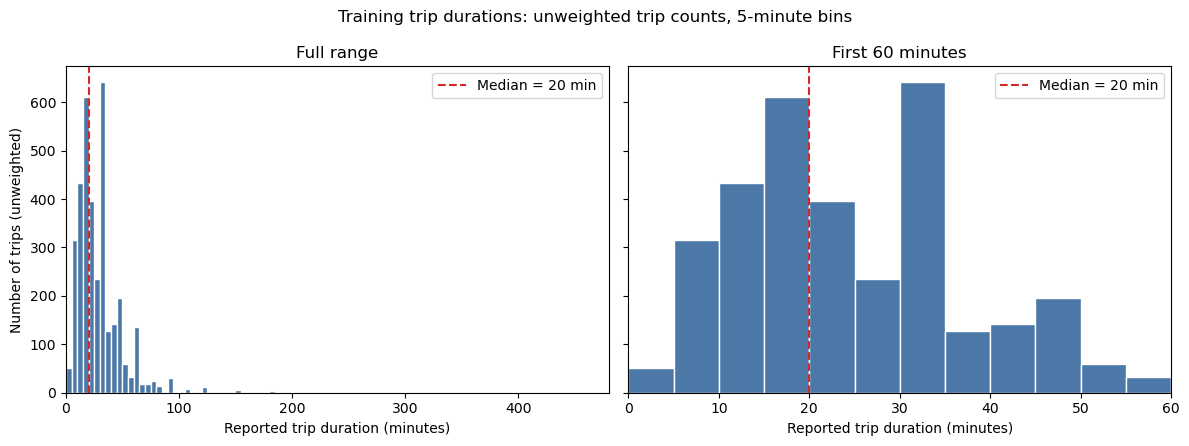

Valid training durations plotted: 3513
Equals 3513: True
Largest duration: 480.0 minutes; median: 20.0 minutes


In [84]:
# Plot the distribution of training trip durations
# matplotlib is not in the shared imports; it is imported here, where it is used.
import matplotlib.pyplot as plt

# valid_minutes: the valid training durations (0 included) from the summary cell.
duration_values = valid_minutes
median_minutes = duration_values.median()

# 5-minute bins starting at 0. They cover at least 0-480 and the observed maximum.
last_bin_edge = max(480, int(-(-duration_values.max() // 5) * 5))
bin_edges = list(range(0, last_bin_edge + 5, 5))

figure, (full_axis, zoom_axis) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for axis in (full_axis, zoom_axis):
    axis.hist(duration_values, bins=bin_edges, color="#4c78a8", edgecolor="white")
    axis.axvline(median_minutes, color="#d62728", linestyle="--", linewidth=1.5,
                 label=f"Median = {median_minutes:g} min")
    axis.set_xlabel("Reported trip duration (minutes)")
    axis.legend()

full_axis.set_xlim(0, last_bin_edge)
full_axis.set_title("Full range")
full_axis.set_ylabel("Number of trips (unweighted)")

# Same histogram and bins, with the x-axis limited to 0-60 minutes.
zoom_axis.set_xlim(0, 60)
zoom_axis.set_title("First 60 minutes")

figure.suptitle("Training trip durations: unweighted trip counts, 5-minute bins")
figure.tight_layout()
plt.show()

print("Valid training durations plotted:", len(duration_values))
print("Equals 3513:", len(duration_values) == 3513)
print("Largest duration:", duration_values.max(), "minutes; median:", median_minutes, "minutes")


The 3,513 valid training trips show a right-skewed distribution of
reported duration, with a median of 20 minutes and a maximum of 480
minutes. Using five-minute bins, the tallest bar covers 30 to under
35 minutes, followed by 15 to under 20 minutes.

In [85]:
# Inspect exact durations within the tallest five-minute bin
# Reuse the valid training durations (0 included) used for the histogram.
minutes_in_bin = [30, 31, 32, 33, 34]
exact_minute_rows = [
    {"Duration (minutes)": minute, "Trips": int((valid_minutes == minute).sum())}
    for minute in minutes_in_bin   # minutes with 0 trips are kept
]
exact_minute_table = pd.DataFrame(exact_minute_rows)

# Total of the five rows, to compare with the trips from 30 up to (not including) 35 minutes.
five_minute_total = int(exact_minute_table["Trips"].sum())
exact_minute_table = pd.concat(
    [exact_minute_table, pd.DataFrame([{"Duration (minutes)": "Total", "Trips": five_minute_total}])],
    ignore_index=True
)
display(exact_minute_table)

trips_30_to_under_35 = int(((valid_minutes >= 30) & (valid_minutes < 35)).sum())
print("Trips with 30 <= duration < 35 minutes:", trips_30_to_under_35)
print("Total of the five rows equals that count:", five_minute_total == trips_30_to_under_35)


,Duration (minutes),Trips
0,30,621
1,31,9
2,32,5
3,33,4
4,34,3
5,Total,642


Trips with 30 <= duration < 35 minutes: 642
Total of the five rows equals that count: True


Of the 642 training trips lasting 30 to under 35 minutes, 621 (96.73%)
were recorded at exactly 30 minutes. The other 21 trips were spread
across 31–34 minutes. This concentration at a round value is consistent
with possible rounding. Its cause cannot be determined from the counts.

In [86]:
# Compare round durations with adjacent minutes
# Reuse the valid training durations (0 included); values are counted, not changed.
def trips_at_minute(minute):
    """Number of valid training trips recorded at exactly this minute."""
    return int((valid_minutes == minute).sum())

round_minute_rows = [
    {
        "Reference minute": reference,
        "Trips at minute − 1": trips_at_minute(reference - 1),
        "Trips at reference minute": trips_at_minute(reference),
        "Trips at minute + 1": trips_at_minute(reference + 1),
    }
    for reference in range(5, 65, 5)   # 5, 10, ..., 60; a minute with no trips shows 0
]
round_minute_table = pd.DataFrame(round_minute_rows)
display(round_minute_table)


,Reference minute,Trips at minute − 1,Trips at reference minute,Trips at minute + 1
0,5,9,226,15
1,10,12,347,10
2,15,14,554,12
3,20,8,364,7
4,25,5,199,9
5,30,13,621,9
6,35,3,119,1
7,40,2,129,2
8,45,3,189,1
9,50,2,52,1


At all 12 five-minute marks from 5 through 60 minutes, the number of
training trips recorded at the mark exceeded the counts at both
adjacent minutes. Together, these 12 values accounted for 2,962 of
3,513 valid training durations (84.3%, unweighted). This pattern is
consistent with rounding. We retain the recorded durations as observed.

In [87]:
# Summarize training trip durations by transport mode
# Reuse the Train rows and the valid-duration rule from the training summary cell:
# train_rows is the Train mask, train_duration_minutes the numeric durations, and
# is_valid_duration keeps readable values of 0 or more (0 kept; -9 and blanks excluded).
# duration_check has the same row order as partitioned_trips, so mode_group lines up by position.
train_mode_group = duration_check["mode_group"].reset_index(drop=True)[train_rows]
train_mode_minutes = pd.DataFrame({
    "mode_group": train_mode_group,
    "minutes": train_duration_minutes.where(is_valid_duration),   # missing/invalid -> NaN, not used
})

# The five study mode groups, in the order defined in the grouping cell.
study_mode_groups = list(mode_group_codes)
mode_duration_rows = []
for group in study_mode_groups:
    group_minutes = train_mode_minutes.loc[train_mode_minutes["mode_group"] == group, "minutes"]
    valid_group_minutes = group_minutes.dropna()
    mode_duration_rows.append({
        "Mode group": group,
        "Train trips": len(group_minutes),
        "Trips with valid duration": len(valid_group_minutes),
        "Q1 (min)": valid_group_minutes.quantile(0.25),
        "Median (min)": valid_group_minutes.median(),
        "Q3 (min)": valid_group_minutes.quantile(0.75),
    })
mode_duration_table = pd.DataFrame(mode_duration_rows)
display(mode_duration_table)

print("Durations are in minutes; statistics are unweighted sample values.")
print("Sum of Train trips:", int(mode_duration_table["Train trips"].sum()),
      "| equals 3516:", int(mode_duration_table["Train trips"].sum()) == 3516)
print("Sum of valid durations:", int(mode_duration_table["Trips with valid duration"].sum()),
      "| equals 3513:", int(mode_duration_table["Trips with valid duration"].sum()) == 3513)


,Mode group,Train trips,Trips with valid duration,Q1 (min),Median (min),Q3 (min)
0,Car/van/SUV/pickup,3314,3312,15.0,20.0,30.0
1,Public transit (bus/rail),65,65,34.0,45.0,60.0
2,Walk,85,84,10.0,15.0,30.0
3,Bike,23,23,10.5,15.0,30.0
4,Other study modes,29,29,10.0,20.0,30.0


Durations are in minutes; statistics are unweighted sample values.
Sum of Train trips: 3516 | equals 3516: True
Sum of valid durations: 3513 | equals 3513: True


In the unweighted training data, median trip duration was 45 minutes
for bus/rail (65 valid trips) and 20 minutes for car/van/SUV/pickup
(3,312 valid trips). The middle 50% ranged from 34 to 60 minutes for
bus/rail and from 15 to 30 minutes for the car group. Walking and
cycling both had a median of 15 minutes, based on 84 and 23 valid
trips, respectively. These descriptive comparisons do not account
for differences in home–work distance.

In [88]:
# Summarize home-work distance by mode for training trips with valid duration
# Training trips with a valid duration (3,513). train_rows, is_valid_duration, and
# train_mode_group come from the earlier cells; partitioned_trips carries GCDWORK and
# the distance status in the same row order (all are indexed by row position).
train_distance = pd.DataFrame({
    "mode_group": train_mode_group,
    "Distance status": partitioned_trips.loc[train_rows, "Distance status"],
    "GCDWORK": partitioned_trips.loc[train_rows, "GCDWORK"],
})
valid_train_distance = train_distance.loc[is_valid_duration]
print("Training trips with valid duration:", len(valid_train_distance))

# Recorded distance = positive distance or zero miles. -1 and -9 stay in separate counts.
recorded_statuses = ["Positive distance", "Zero distance"]
valid_train_distance = valid_train_distance.assign(
    miles=pd.to_numeric(valid_train_distance["GCDWORK"], errors="coerce")
)

distance_mode_rows = []
for group in study_mode_groups:
    in_group = valid_train_distance["mode_group"] == group
    group_rows = valid_train_distance.loc[in_group]
    status = group_rows["Distance status"]
    recorded = status.isin(recorded_statuses)
    recorded_miles = group_rows.loc[recorded, "miles"]
    distance_mode_rows.append({
        "Mode group": group,
        "Trips with valid duration": len(group_rows),
        "Trips with recorded distance": int(recorded.sum()),
        "Appropriate skip (-1)": int((status == "-1 (appropriate skip)").sum()),
        "Not ascertained (-9)": int((status == "-9 (not ascertained)").sum()),
        # Any other status (blank, unmatched Person, other value) is shown separately.
        "Other distance status": int((~recorded & ~status.isin(
            ["-1 (appropriate skip)", "-9 (not ascertained)"])).sum()),
        "Q1 (miles)": recorded_miles.quantile(0.25),
        "Median (miles)": recorded_miles.median(),
        "Q3 (miles)": recorded_miles.quantile(0.75),
    })
distance_mode_table = pd.DataFrame(distance_mode_rows)
display(distance_mode_table)

count_columns = ["Trips with recorded distance", "Appropriate skip (-1)",
                 "Not ascertained (-9)", "Other distance status"]
print("Distances are in miles; statistics are unweighted and computed per trip.")
print("Distance counts add up to the trips with valid duration in every mode group:",
      bool((distance_mode_table[count_columns].sum(axis=1)
            == distance_mode_table["Trips with valid duration"]).all()))
print("Sum of trips with valid duration:", int(distance_mode_table["Trips with valid duration"].sum()),
      "| equals 3513:", int(distance_mode_table["Trips with valid duration"].sum()) == 3513)
print("Trips with an other distance status:", int(distance_mode_table["Other distance status"].sum()))


Training trips with valid duration: 3513


,Mode group,Trips with valid duration,Trips with recorded distance,Appropriate skip (-1),Not ascertained (-9),Other distance status,Q1 (miles),Median (miles),Q3 (miles)
0,Car/van/SUV/pickup,3312,2979,104,229,0,2.680048,6.373187,12.772905
1,Public transit (bus/rail),65,54,6,5,0,2.476997,4.736358,6.403416
2,Walk,84,72,0,12,0,0.335838,0.684696,1.131650
3,Bike,23,22,1,0,0,0.982471,1.927699,2.840033
4,Other study modes,29,25,1,3,0,2.545894,2.868337,4.088723


Distances are in miles; statistics are unweighted and computed per trip.
Distance counts add up to the trips with valid duration in every mode group: True
Sum of trips with valid duration: 3513 | equals 3513: True
Trips with an other distance status: 0


Among training trips with valid duration and recorded home–work distance,
median distance was 4.74 miles for bus/rail (54 trips) and 6.37 miles
for car/van/SUV/pickup (2,979 trips). Median distance was 0.68 miles for
walking and 1.93 miles for cycling. These unweighted, trip-level summaries
describe great-circle home–work distance. Distance coverage varied by mode.

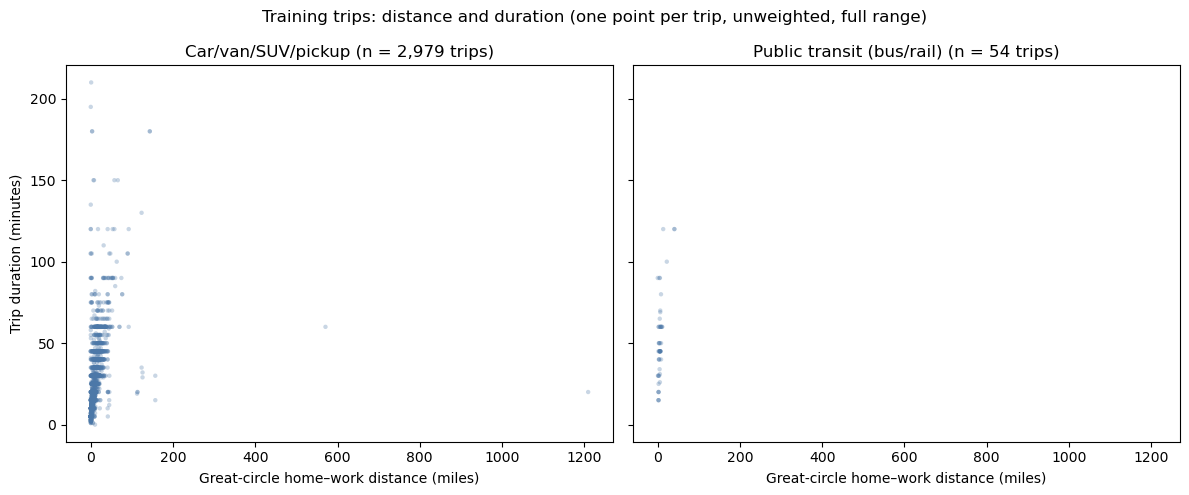

Car/van/SUV/pickup: 2979 trips
Public transit (bus/rail): 54 trips
Car/van/SUV/pickup equals 2979: True
Public transit (bus/rail) equals 54: True


In [89]:
# Plot home-work distance and duration for the same training trips
# Training trips with a valid duration and a recorded distance (0 miles included).
# valid_train_distance (distance cell) has mode_group, miles, and the distance status;
# train_duration_minutes (training summary cell) has the durations, indexed by the same row positions.
scatter_trips = valid_train_distance.assign(
    minutes=train_duration_minutes.loc[valid_train_distance.index]
)
scatter_trips = scatter_trips.loc[scatter_trips["Distance status"].isin(recorded_statuses)]

scatter_groups = ["Car/van/SUV/pickup", "Public transit (bus/rail)"]
figure, scatter_axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for axis, group in zip(scatter_axes, scatter_groups):
    group_trips = scatter_trips.loc[scatter_trips["mode_group"] == group]
    axis.scatter(group_trips["miles"], group_trips["minutes"],
                 s=10, alpha=0.3, color="#4c78a8", edgecolors="none")
    axis.set_title(f"{group} (n = {len(group_trips):,} trips)")
    axis.set_xlabel("Great-circle home–work distance (miles)")
scatter_axes[0].set_ylabel("Trip duration (minutes)")

figure.suptitle("Training trips: distance and duration (one point per trip, unweighted, full range)")
figure.tight_layout()
plt.show()

for group in scatter_groups:
    group_count = int((scatter_trips["mode_group"] == group).sum())
    print(f"{group}: {group_count} trips")
print("Car/van/SUV/pickup equals 2979:",
      int((scatter_trips["mode_group"] == "Car/van/SUV/pickup").sum()) == 2979)
print("Public transit (bus/rail) equals 54:",
      int((scatter_trips["mode_group"] == "Public transit (bus/rail)").sum()) == 54)


Two car-group observations at unusually large home–work distances
stretch the shared horizontal axis and compress the main clusters in
both panels. This limits visual assessment of the distance–duration
relationship over the distances where most trips occur. GCDWORK is
a person-level home–work measure, while duration refers to a specific trip.

In [90]:
# Inspect the two car trips with the largest recorded home-work distances
# The 2,979 plotted car trips: scatter_trips (scatter cell) is indexed by row position,
# and duration_check.index maps each position to its row in the Trip file.
plotted_car_trips = scatter_trips.loc[scatter_trips["mode_group"] == "Car/van/SUV/pickup"]
print("Plotted car trips:", len(plotted_car_trips))

# Columns not held in memory are read from the Trip file; original text is kept.
car_trip_columns = ["TDCASEID", "HOUSEID", "PERSONID", "STRTTIME", "WHYFROM", "WHYTO"]
trip_detail_source = pd.read_csv(
    TRIP_CSV,
    usecols=car_trip_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(trip_detail_source) == len(mode_pair_source), "Trip row count differs from the earlier read"
trip_file_rows = duration_check.index[plotted_car_trips.index]
car_trip_details = trip_detail_source.loc[trip_file_rows].reset_index(drop=True)

# The looked-up rows must belong to the same people as the plotted trips.
assert (car_trip_details["HOUSEID"].to_numpy() == partitioned_trips.loc[plotted_car_trips.index, "HOUSEID"].to_numpy()).all()
assert (car_trip_details["PERSONID"].to_numpy() == partitioned_trips.loc[plotted_car_trips.index, "PERSONID"].to_numpy()).all()

# Add GCDWORK (original text), TRVLCMIN (original text), and the numeric distance for sorting.
car_trip_details["GCDWORK"] = plotted_car_trips["GCDWORK"].to_numpy()
car_trip_details["TRVLCMIN"] = duration_check["TRVLCMIN"].reset_index(drop=True).loc[plotted_car_trips.index].to_numpy()
car_trip_details["miles_for_sorting"] = plotted_car_trips["miles"].to_numpy()

# Two largest distances by numeric value; ties are broken by TDCASEID.
largest_distance_trips = (
    car_trip_details
    .sort_values(["miles_for_sorting", "TDCASEID"], ascending=[False, True])
    .head(2)
    .reset_index(drop=True)
)

# Activity labels reused from the HBW activity-pair cell (Codebook V2.1, Trip sheet).
largest_distance_trips["WHYFROM activity"] = largest_distance_trips["WHYFROM"].map(
    lambda code: label_for(code, from_labels))
largest_distance_trips["WHYTO activity"] = largest_distance_trips["WHYTO"].map(
    lambda code: label_for(code, to_labels))

display(largest_distance_trips[[
    "TDCASEID", "HOUSEID", "PERSONID", "GCDWORK", "TRVLCMIN", "STRTTIME",
    "WHYFROM", "WHYFROM activity", "WHYTO", "WHYTO activity",
]])


Plotted car trips: 2979


,TDCASEID,HOUSEID,PERSONID,GCDWORK,TRVLCMIN,STRTTIME,WHYFROM,WHYFROM activity,WHYTO,WHYTO activity
0,90001705070101,9000170507,01,1209.44841277008,20,0730,01,Regular activities at home,03,Work at a non-home location
1,90002146760201,9000214676,02,570.705393176884,60,1000,01,Regular activities at home,03,Work at a non-home location


The two largest recorded home–work distances in the car group were
1,209.45 and 570.71 miles, paired with trip durations of 20 and 60
minutes. The records belong to different people in different households.
Both trips were coded as travel from home to a non-home work location.
The activity codes do not establish whether each trip ended at the
workplace address used to calculate GCDWORK. Both records were retained.

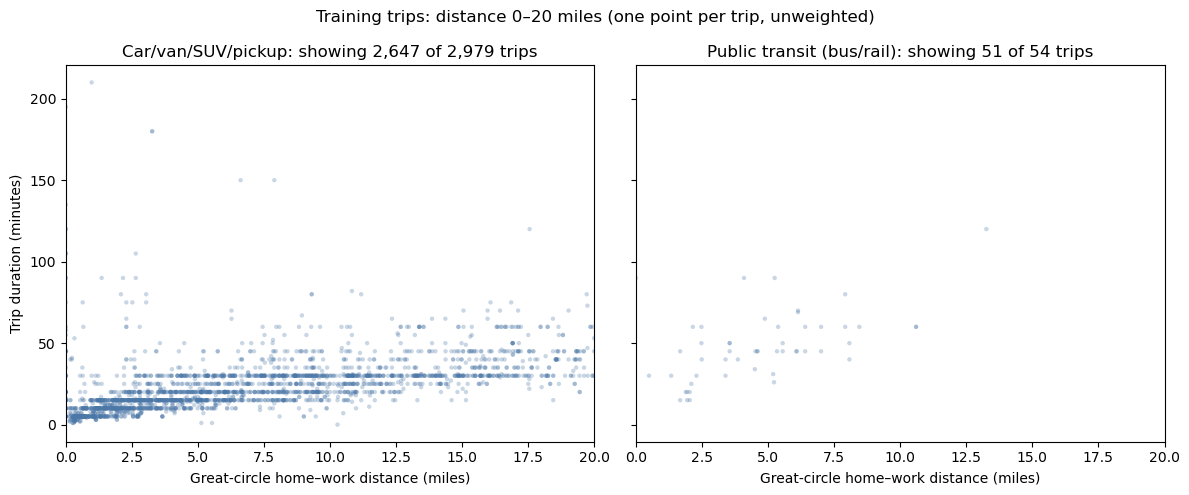

Car/van/SUV/pickup: 2647 visible of 2979 trips
Public transit (bus/rail): 51 visible of 54 trips
Duration axis limits reused from the full-range figure: (-10.5, 220.5)


In [91]:
# Inspect the distance-duration relationship within a 0–20 mile view
# Same training trips as the full-range scatter (scatter_trips); nothing is removed from the data.
# The duration axis keeps the limits of the full-range figure (scatter_axes from the scatter cell).
duration_axis_limits = scatter_axes[0].get_ylim()
zoom_distance_limit = 20   # miles

zoom_figure, zoom_axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for axis, group in zip(zoom_axes, scatter_groups):
    group_trips = scatter_trips.loc[scatter_trips["mode_group"] == group]
    visible_trips = int((group_trips["miles"] <= zoom_distance_limit).sum())
    axis.scatter(group_trips["miles"], group_trips["minutes"],
                 s=10, alpha=0.3, color="#4c78a8", edgecolors="none")
    axis.set_xlim(0, zoom_distance_limit)
    axis.set_ylim(duration_axis_limits)
    axis.set_title(f"{group}: showing {visible_trips:,} of {len(group_trips):,} trips")
    axis.set_xlabel("Great-circle home–work distance (miles)")
zoom_axes[0].set_ylabel("Trip duration (minutes)")

zoom_figure.suptitle("Training trips: distance 0–20 miles (one point per trip, unweighted)")
zoom_figure.tight_layout()
plt.show()

for group in scatter_groups:
    group_trips = scatter_trips.loc[scatter_trips["mode_group"] == group]
    print(f"{group}: {int((group_trips['miles'] <= zoom_distance_limit).sum())} visible of {len(group_trips)} trips")
print("Duration axis limits reused from the full-range figure:", duration_axis_limits)


Within the 0–20 mile view, the densest part of the car-trip distribution
shifts toward longer durations as home–work distance increases. Durations
also vary among trips with similar distances. The view contains 2,647 of
2,979 car trips and 51 of 54 bus/rail trips. The bus/rail observations
are sparse at longer distances, making the trend harder to assess visually.

In [92]:
# Summarize car trip duration across distance bands
# The car trips shown in the 0-20 mile view (exactly 0 and exactly 20 miles are included).
car_trips_in_view = scatter_trips.loc[
    (scatter_trips["mode_group"] == "Car/van/SUV/pickup")
    & (scatter_trips["miles"] >= 0)
    & (scatter_trips["miles"] <= 20)
]

# Four non-overlapping bands: each lower bound is included; only the last band includes 20.
distance_bands = [
    ("0 ≤ d < 5", 0, 5, False),
    ("5 ≤ d < 10", 5, 10, False),
    ("10 ≤ d < 15", 10, 15, False),
    ("15 ≤ d ≤ 20", 15, 20, True),
]
band_rows = []
for band_label, lower, upper, include_upper in distance_bands:
    in_band = car_trips_in_view["miles"] >= lower
    in_band &= (car_trips_in_view["miles"] <= upper) if include_upper else (car_trips_in_view["miles"] < upper)
    band_minutes = car_trips_in_view.loc[in_band, "minutes"]
    band_rows.append({
        "Home–work distance (miles)": band_label,
        "Trips": len(band_minutes),
        "Q1 duration (min)": band_minutes.quantile(0.25),
        "Median duration (min)": band_minutes.median(),
        "Q3 duration (min)": band_minutes.quantile(0.75),
    })
distance_band_table = pd.DataFrame(band_rows)
display(distance_band_table)

print("Statistics are unweighted; the bands describe the plot only.")
print("Car trips in the 0-20 mile view:", len(car_trips_in_view))
print("Sum of the Trips column:", int(distance_band_table["Trips"].sum()),
      "| equals 2647:", int(distance_band_table["Trips"].sum()) == 2647)


,Home–work distance (miles),Trips,Q1 duration (min),Median duration (min),Q3 duration (min)
0,0 ≤ d < 5,1244,10.0,15.0,15.0
1,5 ≤ d < 10,738,17.0,23.5,30.0
2,10 ≤ d < 15,396,25.0,30.0,35.0
3,15 ≤ d ≤ 20,269,30.0,36.0,45.0


Statistics are unweighted; the bands describe the plot only.
Car trips in the 0-20 mile view: 2647
Sum of the Trips column: 2647 | equals 2647: True


Among 2,647 unweighted training car trips with home–work distances of
0–20 miles, median trip duration increased across the four distance
bands: 15, 23.5, 30, and 36 minutes. The middle 50% of durations
ranged from 10–15 minutes in the shortest-distance band and 30–45
minutes in the longest. This pattern supports evaluating home–work
distance as a candidate predictor.

In [93]:
# Compare car and bus/rail median duration across distance bands
# Training trips in the 0-20 mile view with valid duration and recorded distance
# (scatter_trips); exactly 0 and exactly 20 miles are included.
trips_in_view = scatter_trips.loc[
    (scatter_trips["miles"] >= 0) & (scatter_trips["miles"] <= 20)
]
car_in_view = trips_in_view.loc[trips_in_view["mode_group"] == "Car/van/SUV/pickup"]
busrail_in_view = trips_in_view.loc[trips_in_view["mode_group"] == "Public transit (bus/rail)"]

def band_trips_and_median(trips, lower, upper, include_upper):
    """Trip count and median duration in one band; median is 'NA' when the band has no trips."""
    in_band = trips["miles"] >= lower
    in_band &= (trips["miles"] <= upper) if include_upper else (trips["miles"] < upper)
    band_minutes = trips.loc[in_band, "minutes"]
    median_minutes = band_minutes.median() if len(band_minutes) > 0 else "NA"
    return len(band_minutes), median_minutes

# distance_bands (labels and boundaries) comes from the previous distance-band cell.
comparison_rows = []
for band_label, lower, upper, include_upper in distance_bands:
    car_count, car_median = band_trips_and_median(car_in_view, lower, upper, include_upper)
    busrail_count, busrail_median = band_trips_and_median(busrail_in_view, lower, upper, include_upper)
    comparison_rows.append({
        "Distance band (miles)": band_label,
        "Car trips": car_count,
        "Car median (min)": car_median,
        "Bus/rail trips": busrail_count,
        "Bus/rail median (min)": busrail_median,
    })
mode_band_table = pd.DataFrame(comparison_rows)
display(mode_band_table)

print("Statistics are unweighted; a band with no trips shows 0 trips and NA.")
print("Car trips in the table:", int(mode_band_table["Car trips"].sum()),
      "| equals 2647:", int(mode_band_table["Car trips"].sum()) == 2647)
print("Bus/rail trips in the table:", int(mode_band_table["Bus/rail trips"].sum()),
      "| equals 51:", int(mode_band_table["Bus/rail trips"].sum()) == 51)


,Distance band (miles),Car trips,Car median (min),Bus/rail trips,Bus/rail median (min)
0,0 ≤ d < 5,1244,15.0,28,40.0
1,5 ≤ d < 10,738,23.5,20,50.0
2,10 ≤ d < 15,396,30.0,3,60.0
3,15 ≤ d ≤ 20,269,36.0,0,NA


Statistics are unweighted; a band with no trips shows 0 trips and NA.
Car trips in the table: 2647 | equals 2647: True
Bus/rail trips in the table: 51 | equals 51: True


In the unweighted training data, median duration was 40 minutes for
bus/rail and 15 minutes for car trips below 5 miles. From 5 to under
10 miles, the corresponding medians were 50 and 23.5 minutes. These
two bands contained 48 of the 51 bus/rail trips in the 0–20 mile view.
Only three bus/rail trips were observed from 10 to under 15 miles,
and none from 15 to 20 miles. The observed differences motivate
evaluating transport mode alongside home–work distance in prediction.

In [94]:
# Count training trips by departure hour and trip direction
# Training trips with a valid duration (3,513): valid_train_distance is indexed by row position,
# and duration_check.index maps each position to its row in the Trip file.
departure_columns = ["HOUSEID", "PERSONID", "STRTTIME", "WHYFROM", "WHYTO"]
departure_source = pd.read_csv(
    TRIP_CSV,
    usecols=departure_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(departure_source) == len(mode_pair_source), "Trip row count differs from the earlier read"
departure_trips = departure_source.loc[duration_check.index[valid_train_distance.index]].reset_index(drop=True)

# The looked-up rows must belong to the same people as the training trips.
assert (departure_trips["HOUSEID"].to_numpy() == partitioned_trips.loc[valid_train_distance.index, "HOUSEID"].to_numpy()).all()
assert (departure_trips["PERSONID"].to_numpy() == partitioned_trips.loc[valid_train_distance.index, "PERSONID"].to_numpy()).all()
print("Training trips with valid duration:", len(departure_trips))

# Direction from the HBW construction in the Derived Variables (DV p. 15):
# home = WHYFROM/WHYTO 01 or 02; work = 03, 04, or 05.
home_codes = ["01", "02"]
work_codes = ["03", "04", "05"]
home_to_work = departure_trips["WHYFROM"].isin(home_codes) & departure_trips["WHYTO"].isin(work_codes)
work_to_home = departure_trips["WHYFROM"].isin(work_codes) & departure_trips["WHYTO"].isin(home_codes)
direction_unclassified = ~(home_to_work | work_to_home)

# STRTTIME is read as HHMM: four digits, hour 00-23, minute 00-59. The original text is kept.
valid_start_time = (
    departure_trips["STRTTIME"]
    .str.fullmatch(r"([01][0-9]|2[0-3])[0-5][0-9]")
    .fillna(False)
    .astype(bool)
)
start_hour = pd.to_numeric(departure_trips["STRTTIME"].str[:2], errors="coerce")
invalid_time = ~valid_start_time

# One row per hour 0-23; hours with no trips stay in the table.
hour_rows = []
for hour in range(24):
    in_hour = valid_start_time & (start_hour == hour)
    hour_rows.append({
        "Departure hour": hour,
        "Home-to-work trips": int((in_hour & home_to_work).sum()),
        "Work-to-home trips": int((in_hour & work_to_home).sum()),
    })
departure_hour_table = pd.DataFrame(hour_rows)
display(departure_hour_table)

# Trips outside the table: invalid time or unclassified direction (a trip with both problems is counted once).
outside_table = invalid_time | direction_unclassified
table_total = int(departure_hour_table[["Home-to-work trips", "Work-to-home trips"]].sum().sum())
print("Trips with missing or invalid start time:", int(invalid_time.sum()))
print("Trips with unclassified direction:", int(direction_unclassified.sum()))
print("Trips with both problems:", int((invalid_time & direction_unclassified).sum()))
print("Trips outside the table (counted once):", int(outside_table.sum()))
print("Trips in the table:", table_total)
print("Table plus outside trips equals 3513:", table_total + int(outside_table.sum()) == 3513)


Training trips with valid duration: 3513


,Departure hour,Home-to-work trips,Work-to-home trips
0,0,0,8
1,1,0,1
2,2,0,2
3,3,3,4
4,4,42,2
5,5,171,1
6,6,297,2
7,7,511,5
8,8,335,9
9,9,148,11


Trips with missing or invalid start time: 0
Trips with unclassified direction: 0
Trips with both problems: 0
Trips outside the table (counted once): 0
Trips in the table: 3513
Table plus outside trips equals 3513: True


All 3,513 training trips with valid duration had a valid departure hour
and a classified direction. Home-to-work departures peaked at 07:00–07:59
(511 trips), while work-to-home departures peaked at 17:00–17:59
(377 trips). Because the mix of directions changes across the day,
we examine duration by departure hour within each direction.

In [95]:
# Compare median trip duration by departure hour within each direction
# Same 3,513 training trips, hour variable, and direction rule as the previous cell
# (departure_trips, valid_start_time, start_hour, home_to_work, work_to_home).
# Durations come from train_duration_minutes, aligned to the same row positions.
trip_minutes = train_duration_minutes.loc[valid_train_distance.index].reset_index(drop=True)
assert len(trip_minutes) == len(departure_trips)

def trips_and_median(direction_mask, hour):
    """Trip count and median duration for one direction and hour; median is 'NA' with no trips."""
    in_cell = valid_start_time & (start_hour == hour) & direction_mask
    minutes_in_cell = trip_minutes[in_cell]
    median_minutes = minutes_in_cell.median() if len(minutes_in_cell) > 0 else "NA"
    return len(minutes_in_cell), median_minutes

# One row per hour 0-23, so hours with no trips stay in the table.
median_hour_rows = []
for hour in range(24):
    home_work_count, home_work_median = trips_and_median(home_to_work, hour)
    work_home_count, work_home_median = trips_and_median(work_to_home, hour)
    median_hour_rows.append({
        "Departure hour": hour,
        "Home-to-work trips": home_work_count,
        "Home-to-work median (min)": home_work_median,
        "Work-to-home trips": work_home_count,
        "Work-to-home median (min)": work_home_median,
    })
median_by_hour_table = pd.DataFrame(median_hour_rows)
display(median_by_hour_table)

print("Medians are unweighted; an hour with no trips shows 0 trips and NA.")
home_work_total = int(median_by_hour_table["Home-to-work trips"].sum())
work_home_total = int(median_by_hour_table["Work-to-home trips"].sum())
print("Home-to-work trips:", home_work_total, "| equals 1879:", home_work_total == 1879)
print("Work-to-home trips:", work_home_total, "| equals 1634:", work_home_total == 1634)


,Departure hour,Home-to-work trips,Home-to-work median (min),Work-to-home trips,Work-to-home median (min)
0,0,0,NA,8,17.5
1,1,0,NA,1,35.0
2,2,0,NA,2,19.5
3,3,3,25.0,4,32.5
4,4,42,20.0,2,17.5
5,5,171,30.0,1,15.0
6,6,297,25.0,2,15.0
7,7,511,22.0,5,35.0
8,8,335,20.0,9,15.0
9,9,148,20.0,11,20.0


Medians are unweighted; an hour with no trips shows 0 trips and NA.
Home-to-work trips: 1879 | equals 1879: True
Work-to-home trips: 1634 | equals 1634: True


In the unweighted training sample, home-to-work departures peaked at
07:00–07:59 (511 trips), with a median duration of 22 minutes. The
corresponding medians were 25 minutes at 06:00 and 20 minutes at 08:00.
For work-to-home travel, the busiest departure hour was 17:00 (377 trips,
median 25 minutes), while the median at 16:00 was 30 minutes. These
comparisons are descriptive and do not adjust for distance or mode.

### URBRUR: household urban/rural classification

`URBRUR` was not yet in the dictionary. It describes where the **household lives**, not where a trip
takes place, so every trip of a household carries the same value.

| Item | Entry |
|---|---|
| Official definition | Household in urban/rural area ([CB] Trip sheet, row 557; Data Dictionary row 210) |
| Source table | Trip, `tripv2pub.csv` (the header contains `URBRUR`); also listed for Household, Person, Vehicle, and Long Distance |
| Data type | C, length 2; categorical code, no physical unit. Keep as text. |
| Codes | `01` = Urban; `02` = Rural ([CB], V2.1, Trip sheet rows 557-558, PDF p. 58) |
| Missing and skip codes | None listed in the Trip entry; this does not show that the local CSV has no blank or invalid values. |
| Derivation | [DV], p. 17: `URBRUR = 01` if `URBAN` is `01` or `02`, otherwise `02`. `URBAN` (p. 16) is the household's urban-area classification from the home address and the 2020 TIGER/Line shapefile, so `URBRUR = 02` also includes households coded `03` (surrounded by urban areas) or `04` (not in an urban area). |
| Project role | Candidate residential-context predictor; original public-use field, provider-derived |


In [96]:
# Check residential context coverage in the training sample
# URBRUR is not held in memory, so read it from the Trip file for the 3,513 training trips
# with valid duration (valid_train_distance is indexed by row position; duration_check.index
# maps each position to its row in the Trip file).
urban_rural_columns = ["TDCASEID", "HOUSEID", "PERSONID", "URBRUR"]
urban_rural_source = pd.read_csv(
    TRIP_CSV,
    usecols=urban_rural_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(urban_rural_source) == len(mode_pair_source), "Trip row count differs from the earlier read"
urban_rural_trips = urban_rural_source.loc[duration_check.index[valid_train_distance.index]].reset_index(drop=True)

# Rows kept, trip identifiers unique, and the same people as the training trips.
assert len(urban_rural_trips) == len(valid_train_distance), "Row count changed"
assert urban_rural_trips["TDCASEID"].is_unique, "Duplicate TDCASEID in the lookup"
assert (urban_rural_trips["HOUSEID"].to_numpy() == partitioned_trips.loc[valid_train_distance.index, "HOUSEID"].to_numpy()).all()
assert (urban_rural_trips["PERSONID"].to_numpy() == partitioned_trips.loc[valid_train_distance.index, "PERSONID"].to_numpy()).all()
print("Training trips with valid duration:", len(urban_rural_trips))

# URBRUR labels from the local Codebook V2.1, sheet "Trip" (rows 557-558).
codebook_workbook = load_workbook(CODEBOOK_XLSX, read_only=True)
try:
    urban_rural_labels, in_urbrur = {}, False
    for row in codebook_workbook["Trip"].iter_rows(values_only=True):
        if row[0] == "URBRUR":
            in_urbrur = True
        elif row[0]:
            in_urbrur = False
        if in_urbrur and row[4] and "=" in str(row[4]):
            code, label = str(row[4]).split("=", 1)
            urban_rural_labels[code.strip()] = label.strip()
finally:
    codebook_workbook.close()

def residential_label(code):
    """Label a code; blanks and codes outside the Codebook list stay visible."""
    if code.strip() == "":
        return "Blank"
    return urban_rural_labels.get(code, "Code not in Codebook list")

# One row per observed code, with trips and distinct households (HOUSEID).
residential_rows = []
for code in sorted(urban_rural_trips["URBRUR"].unique()):
    in_code = urban_rural_trips["URBRUR"] == code
    residential_rows.append({
        "URBRUR code": code if code.strip() else "(blank)",
        "Residential context": residential_label(code),
        "Trips": int(in_code.sum()),
        "Distinct households": urban_rural_trips.loc[in_code, "HOUSEID"].nunique(),
    })
residential_table = pd.DataFrame(residential_rows)
total_row = pd.DataFrame([{
    "URBRUR code": "Total", "Residential context": "",
    "Trips": len(urban_rural_trips),
    "Distinct households": urban_rural_trips["HOUSEID"].nunique(),
}])
residential_table = pd.concat([residential_table, total_row], ignore_index=True)
display(residential_table)

# Checks: total trips, and households that appear under more than one URBRUR code.
households_in_several_groups = int(
    (urban_rural_trips.groupby("HOUSEID")["URBRUR"].nunique() > 1).sum()
)
print("Total trips equals 3513:", len(urban_rural_trips) == 3513)
print("Households appearing in more than one residential group:", households_in_several_groups)
print("Counts are unweighted.")


Training trips with valid duration: 3513


,URBRUR code,Residential context,Trips,Distinct households
0,01,Urban,2790,1235
1,02,Rural,723,316
2,Total,,3513,1551


Total trips equals 3513: True
Households appearing in more than one residential group: 0
Counts are unweighted.


Among the 3,513 training trips with valid duration, 2,790 (79.4%) were
made by members of urban households and 723 (20.6%) by members of rural
households. The groups comprised 1,235 and 316 distinct households,
respectively. No household appeared in both groups. These are unweighted
sample counts based on household residence.

In [97]:
# Summarize training trip duration by household residence
# Same 3,513 training trips and URBRUR decoding as the coverage cell
# (urban_rural_trips and residential_label); durations come from train_duration_minutes,
# aligned to the same row positions. Duration 0 is kept.
residence_minutes = train_duration_minutes.loc[valid_train_distance.index].reset_index(drop=True)
assert len(residence_minutes) == len(urban_rural_trips)

residence_rows = []
for code in ["01", "02"]:   # Urban, Rural
    in_group = urban_rural_trips["URBRUR"] == code
    group_minutes = residence_minutes[in_group.to_numpy()]
    residence_rows.append({
        "Residential context": residential_label(code),
        "Trips": len(group_minutes),
        "Distinct households": urban_rural_trips.loc[in_group, "HOUSEID"].nunique(),
        "Q1 duration (min)": group_minutes.quantile(0.25),
        "Median duration (min)": group_minutes.median(),
        "Q3 duration (min)": group_minutes.quantile(0.75),
    })
residence_duration_table = pd.DataFrame(residence_rows)
display(residence_duration_table)

print("Quantiles are per trip and unweighted; durations are in minutes.")
urban_trips = int(residence_duration_table.loc[0, "Trips"])
rural_trips = int(residence_duration_table.loc[1, "Trips"])
print("Urban trips:", urban_trips, "| equals 2790:", urban_trips == 2790)
print("Rural trips:", rural_trips, "| equals 723:", rural_trips == 723)
print("Urban plus Rural equals 3513:", urban_trips + rural_trips == 3513)


,Residential context,Trips,Distinct households,Q1 duration (min),Median duration (min),Q3 duration (min)
0,Urban,2790,1235,15.0,20.0,30.0
1,Rural,723,316,15.0,25.0,35.0


Quantiles are per trip and unweighted; durations are in minutes.
Urban trips: 2790 | equals 2790: True
Rural trips: 723 | equals 723: True
Urban plus Rural equals 3513: True


Among training trips with valid duration, the unweighted median was
25 minutes for rural residents (723 trips) and 20 minutes for urban
residents (2,790 trips). The first quartile was 15 minutes in both
groups, while the third quartile was 35 minutes for rural residents
and 30 minutes for urban residents. These trip-level summaries describe
household residence and do not adjust for distance or transport mode.

In [98]:
# Check weekday trip weight coverage in the calendar-weekday training sample
# Read TRAVDAY and WTTRDFIN5D (and STRTTIME for a consistency check) from the Trip file for the
# 3,513 training trips with valid duration. valid_train_distance is indexed by row position and
# duration_check.index maps each position to its row in the Trip file.
weight_columns = ["HOUSEID", "PERSONID", "TRAVDAY", "STRTTIME", "WTTRDFIN5D"]
weight_source = pd.read_csv(
    TRIP_CSV,
    usecols=weight_columns,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig"
)
assert len(weight_source) == len(mode_pair_source), "Trip row count differs from the earlier read"
weight_trips = weight_source.loc[duration_check.index[valid_train_distance.index]].reset_index(drop=True)

# Same people and same start times as the departure-hour cell (departure_trips).
assert len(weight_trips) == len(departure_trips)
assert (weight_trips["HOUSEID"] == departure_trips["HOUSEID"]).all()
assert (weight_trips["PERSONID"] == departure_trips["PERSONID"]).all()
assert (weight_trips["STRTTIME"] == departure_trips["STRTTIME"]).all()
print("Training trips with valid duration:", len(weight_trips))

# Day groups. Friday is split by start time using the HHMM check and hour from the departure-hour
# cell (valid_start_time, start_hour); a Friday trip with a missing or invalid time is kept apart.
is_friday = weight_trips["TRAVDAY"] == "06"
day_groups = {
    "Monday–Thursday": weight_trips["TRAVDAY"].isin(["02", "03", "04", "05"]),
    "Friday before 18:00": is_friday & valid_start_time & (start_hour < 18),
    "Friday at or after 18:00": is_friday & valid_start_time & (start_hour >= 18),
    "Friday with missing or invalid start time": is_friday & ~valid_start_time,
}
day_groups["Other TRAVDAY code"] = ~(
    day_groups["Monday–Thursday"] | is_friday
)

# WTTRDFIN5D status from the original text. Negative, blank, and unreadable values are invalid.
weight_numeric = pd.to_numeric(weight_trips["WTTRDFIN5D"], errors="coerce").astype("float64")
weight_positive = weight_numeric > 0
weight_zero = weight_numeric == 0
weight_invalid = ~(weight_positive | weight_zero)

weight_rows = []
for group_name, in_group in day_groups.items():
    weight_rows.append({
        "Day group": group_name,
        "Trips": int(in_group.sum()),
        "Positive WTTRDFIN5D": int((in_group & weight_positive).sum()),
        "Zero WTTRDFIN5D": int((in_group & weight_zero).sum()),
        "Missing or invalid WTTRDFIN5D": int((in_group & weight_invalid).sum()),
    })
weight_coverage = pd.DataFrame(weight_rows)
total_row = {"Day group": "Total"}
total_row.update({column: int(weight_coverage[column].sum()) for column in weight_coverage.columns[1:]})
weight_coverage = pd.concat([weight_coverage, pd.DataFrame([total_row])], ignore_index=True)
display(weight_coverage)

# Checks: statuses add up to the trips in every row, and the total is 3,513.
status_columns = ["Positive WTTRDFIN5D", "Zero WTTRDFIN5D", "Missing or invalid WTTRDFIN5D"]
print("Weight statuses add up to Trips in every row:",
      bool((weight_coverage[status_columns].sum(axis=1) == weight_coverage["Trips"]).all()))
print("Total trips equals 3513:", int(weight_coverage.loc[weight_coverage["Day group"] == "Total", "Trips"].iloc[0]) == 3513)
print("Counts are unweighted trip counts; no trip was removed.")


Training trips with valid duration: 3513


,Day group,Trips,Positive WTTRDFIN5D,Zero WTTRDFIN5D,Missing or invalid WTTRDFIN5D
0,Monday–Thursday,2863,2863,0,0
1,Friday before 18:00,576,576,0,0
2,Friday at or after 18:00,74,74,0,0
3,Friday with missing or invalid start time,0,0,0,0
4,Other TRAVDAY code,0,0,0,0
5,Total,3513,3513,0,0


Weight statuses add up to Trips in every row: True
Total trips equals 3513: True
Counts are unweighted trip counts; no trip was removed.


All 3,513 training trips with valid duration had a positive five-day trip
weight (`WTTRDFIN5D`), including all 74 Friday trips departing at or after
18:00. These are unweighted trip counts.

The NHTS User’s Guide (Section 7.2, p. 24; PDF p. 28) states that five-day
weights “should be used for weekday travel estimates.” That section does
not define “weekday” or explicitly address Friday evenings. It therefore
leaves open whether its recommendation covers all trips under this study’s
Monday–Friday definition. The check confirms positive weights throughout
the sample examined; their magnitudes and influence on estimates have yet
to be assessed.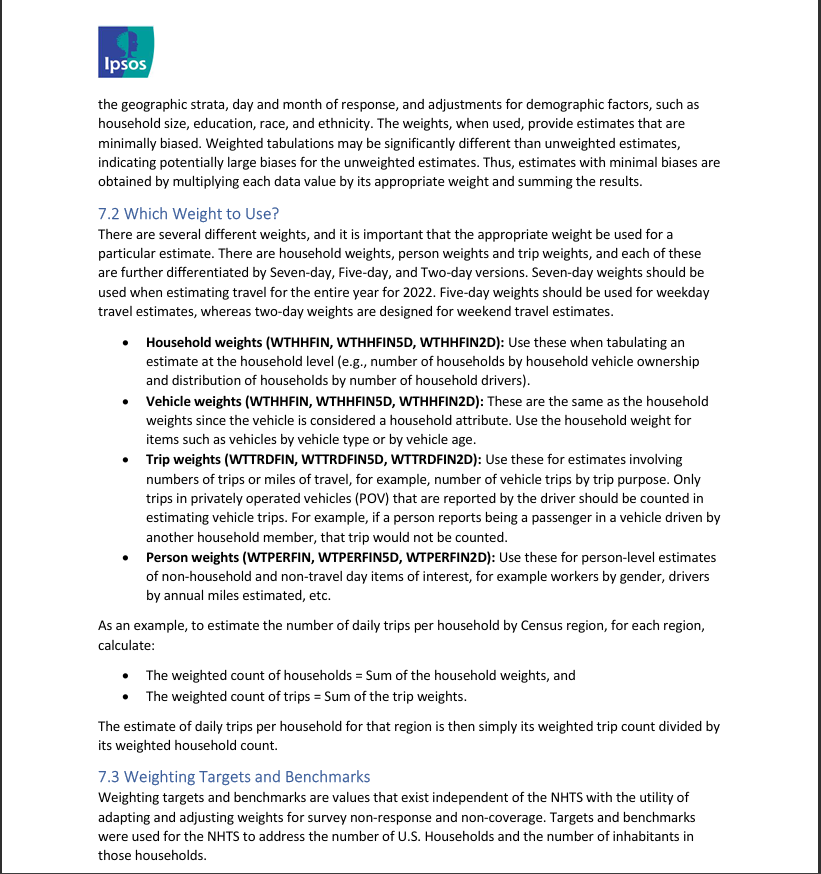

In [99]:
# Compare unweighted and WTTRDFIN5D-weighted median trip duration in the training sample
# Same 3,513 training trips and valid-duration rule as the weight-coverage cell; the 74 Friday
# evening trips stay in (Monday-Friday definition). weight_numeric comes from that cell, and
# the durations are aligned to the same row positions.
training_minutes = train_duration_minutes.loc[valid_train_distance.index].reset_index(drop=True)
assert len(training_minutes) == len(weight_numeric)

# Unweighted median, recomputed from the data.
unweighted_median = training_minutes.median()

# Weighted median: add up the weights of trips with the same duration, sort durations from
# smallest to largest, accumulate the weights, and take the smallest duration whose
# cumulative weight reaches at least 50% of the total weight.
duration_weight = pd.DataFrame({"minutes": training_minutes, "weight": weight_numeric})
weights_by_duration = duration_weight.groupby("minutes")["weight"].sum().sort_index()
cumulative_weight = weights_by_duration.cumsum()
half_of_total_weight = 0.5 * weights_by_duration.sum()
weighted_median = cumulative_weight[cumulative_weight >= half_of_total_weight].index[0]

median_comparison = pd.DataFrame({
    "Method": ["Unweighted", "Weighted by WTTRDFIN5D"],
    "Trips used": [len(training_minutes), int(duration_weight["weight"].notna().sum())],
    "Median duration (min)": [unweighted_median, weighted_median],
})
display(median_comparison)

# Checks: both rows use the same 3,513 trips, and the unweighted median matches the earlier 20 minutes.
print("Both rows use 3513 trips:",
      bool((median_comparison["Trips used"] == 3513).all()))
print("Unweighted median equals 20 minutes:", unweighted_median == 20)


,Method,Trips used,Median duration (min)
0,Unweighted,3513,20.0
1,Weighted by WTTRDFIN5D,3513,24.0


Both rows use 3513 trips: True
Unweighted median equals 20 minutes: True


Across the same 3,513 training trips with valid duration, the unweighted median was 20 minutes and the median weighted by `WTTRDFIN5D` was 24 minutes. Both calculations included the 74 Friday trips departing at or after 18:00 under the study’s calendar-weekday definition.

**Decision.** We retained the 74 Friday-evening trips because the study defines weekdays as Monday through Friday by calendar day. We use the unweighted median to describe the training sample and report the `WTTRDFIN5D`-weighted median as a sensitivity check. Whether the five-day weight is intended to cover Friday departures at or after 18:00 remains unresolved.

In [100]:
# Sensitivity check: exclude Friday departures at or after 18:00
# Reuse the 3,513 training trips with valid duration (training_minutes), their WTTRDFIN5D
# weights (weight_numeric), and the Friday-evening mask from the weight-coverage cell
# (day_groups["Friday at or after 18:00"]). The filter below is temporary; the main
# sample and these variables are not changed.
friday_evening = day_groups["Friday at or after 18:00"]
assert len(training_minutes) == len(weight_numeric) == len(friday_evening)

def weighted_median(minutes, weights):
    """Smallest duration whose cumulative weight reaches at least 50% of the total weight."""
    weights_by_duration = (
        pd.DataFrame({"minutes": minutes, "weight": weights})
        .groupby("minutes")["weight"].sum().sort_index()
    )
    cumulative_weight = weights_by_duration.cumsum()
    return cumulative_weight[cumulative_weight >= 0.5 * weights_by_duration.sum()].index[0]

sample_definitions = [
    ("All calendar-weekday training trips with valid duration", pd.Series(True, index=training_minutes.index)),
    ("Excluding Friday departures at or after 18:00", ~friday_evening),
]
sensitivity_rows = []
for sample_name, keep in sample_definitions:
    sample_minutes = training_minutes[keep]
    sample_weights = weight_numeric[keep]
    sensitivity_rows.append({
        "Sample": sample_name,
        "Trips": len(sample_minutes),
        "Unweighted median (min)": sample_minutes.median(),
        "WTTRDFIN5D-weighted median (min)": weighted_median(sample_minutes, sample_weights),
    })
friday_evening_sensitivity = pd.DataFrame(sensitivity_rows)
display(friday_evening_sensitivity)

# Checks: row 1 reproduces the earlier results; row 2 drops exactly the 74 Friday-evening trips.
first_row, second_row = friday_evening_sensitivity.iloc[0], friday_evening_sensitivity.iloc[1]
print("Row 1 has 3513 trips:", first_row["Trips"] == 3513)
print("Row 1 medians equal 20 and 24 minutes:",
      first_row["Unweighted median (min)"] == 20 and first_row["WTTRDFIN5D-weighted median (min)"] == 24)
print("Trips removed in row 2:", int(first_row["Trips"] - second_row["Trips"]),
      "| equals 74:", int(first_row["Trips"] - second_row["Trips"]) == 74)
print("Row 2 has 3439 trips:", second_row["Trips"] == 3439)


,Sample,Trips,Unweighted median (min),WTTRDFIN5D-weighted median (min)
0,All calendar-weekday training trips with valid...,3513,20.0,24.0
1,Excluding Friday departures at or after 18:00,3439,20.0,25.0


Row 1 has 3513 trips: True
Row 1 medians equal 20 and 24 minutes: True
Trips removed in row 2: 74 | equals 74: True
Row 2 has 3439 trips: True


Temporarily excluding the 74 Friday departures at or after 18:00 reduced the sample from 3,513 to 3,439 training trips. The unweighted median remained at 20 minutes, while the `WTTRDFIN5D`-weighted median increased from 24 to 25 minutes. The gap between the two medians therefore persisted under both sample definitions.

## Variable Decisions and Preprocessing

### Outcome: recorded trip duration (`TRVLCMIN`)

We use recorded trip duration in minutes as the outcome. Of the 3,516 training trips, 3,513 have an observed duration. The remaining three carry code `-9` (not ascertained). We retain them in the sample accounting and exclude them from analyses that require an observed outcome. We do not impute trip duration.

We retain the recorded zero. For that trip, both departure and arrival were recorded as 06:15, so the timestamps support a duration of zero at the available minute resolution. We also retain the observed concentrations at multiples of five minutes and the maximum of 480 minutes. All observed durations enter the analysis in their original units.

### Predictor: home–work distance (`GCDWORK`)

`GCDWORK` measures the great-circle distance in miles between a person's home and workplace. Trips made by the same person share this value. The distance travelled on an individual trip can differ from this measure.

Of the 3,513 training trips with observed duration, 3,152 had a recorded home–work distance, 112 had an appropriate skip (`-1`), and 249 had distance not ascertained (`-9`). Requiring a recorded distance would exclude 361 trips (10.28%).

We retain these trips and preserve the distinction between the two missing-distance statuses. A recorded zero remains a valid distance. For preprocessing, only recorded distances enter the numeric distance field, and a separate status field identifies recorded distance, appropriate skip, or not ascertained. Model-specific handling of missing numeric distances remains open.

### Predictor: transport mode (`TRPTRANS`)

We retain the original `TRPTRANS` code and use a five-category predictor: car/van/SUV/pickup, public transit, walk, bike, and other study modes. All 3,513 training trips with observed duration fall into one of these groups. We retain trips in every group.

The public-transit group combines bus, streetcar/trolley, subway/elevated rail, and commuter rail. All four detailed modes map to Public Transit in `TRIPMODE`. The `Other study modes` group pools motorcycle, other ride-sharing service, paratransit, and other specified modes. This group represents several distinct ways of travelling.

We treat mode as an unordered category. Using recorded mode for a pre-departure prediction assumes that the traveller's mode is already known at prediction time.

### Predictor: departure time (`STRTTIME`)

All 3,513 training trips with observed duration had a valid recorded start time. Departures varied by direction. For example, 511 home-to-work trips and five work-to-home trips started between 07:00 and 07:59.

We retain the original local departure time and parse its hour and minute components. The hourly groups were used for exploration. The choice of time representation for prediction remains open. Using recorded departure time for a pre-departure prediction assumes that the intended departure time is available.

### Predictor: trip direction (`WHYFROM`, `WHYTO`)

We derive direction from the activities at the two ends of each selected home-based work trip. A trip from a home-side activity (codes `01` or `02`) to a work-side activity (`03`, `04`, or `05`) is classified as home-to-work. The reverse combination is classified as work-to-home.

This rule classified all 3,513 training trips with observed duration: 1,879 home-to-work and 1,634 work-to-home. We retain direction as a categorical predictor. At prediction time, the intended origin and destination activities must be known.

### Predictor: residential context (`URBRUR`)

We use household residential context as a two-category predictor: urban (`01`) or rural (`02`). Among training trips with observed duration, 2,790 trips were associated with urban households and 723 with rural households. Each household appeared in one residential group.

The unweighted median duration was 20 minutes for urban trips and 25 minutes for rural trips. The middle 50% ranged from 15 to 30 minutes in the urban group and from 15 to 35 minutes in the rural group. These summaries describe residential context at the traveller's home. They do not establish how much this predictor adds once distance, mode, and departure time are considered.

### EDA checkpoint and handoff to modelling

The training partition contains 3,516 trips. Of these, 3,513 have an observed duration and contribute to the outcome summaries. Their unweighted median duration was 20 minutes. The modelling target is the conditional median trip duration given the information available before departure.

We carry forward five predictor groups: home–work distance and its recording status, transport mode, departure time, trip direction, and household residential context. The distance bands and hourly tables used in EDA were descriptive. Final encoding and model-specific handling of missing distances will be evaluated within training data.

The weighted median was 24 minutes when all calendar-weekday trips with observed duration were included and 25 minutes when Friday departures at or after 18:00 were temporarily excluded. The primary sample retains those departures. The intended Friday-evening coverage of the five-day weight and the choice of training weights remain open.

The next stage will compare predictions against a median baseline using household-grouped validation within the training partition. Earlier full-sample exploration is documented in the project history and should be disclosed when interpreting the eventual test evaluation.